# Example of generating a 1D2DRR D-HYDRO model - an overview of functionalities

This notebook gives an overview of the functionalities of the D-HyDAMO module, part of the Hydrolib environment.

This notebook is based on previous examples of the python package delft3dfmpy, but now connnected to the Hydrolib-core package, which is used for writing a D-HYDRO model. It contains similar functionalities as delft3dfmpy 2.0.3; input data is expected to be according to HyDAMO DAMO2.2 gpkg-format. The example model used here is based on a part of the Oostrumsche beek in Limburg, added with some fictional dummy data to better illustrate functionalities.

Because of the dummy data and demonstation of certain features, the resulting model is not optimal from a hydrologic point of view.



## Load Python libraries and Hydrolib-core functionality

In [1]:
# Basis
import warnings
from pathlib import Path
import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from shapely.geometry import Point, Polygon

warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:
# and from hydrolib-core
from hydrolib.core.dflowfm.crosssection.models import CrossDefModel, CrossLocModel
from hydrolib.core.dflowfm.ext.models import ExtModel
from hydrolib.core.dflowfm.friction.models import FrictionModel
from hydrolib.core.dflowfm.inifield.models import DiskOnlyFileModel, IniFieldModel
from hydrolib.core.dflowfm.mdu.models import FMModel
from hydrolib.core.dflowfm.obs.models import ObservationPointModel
from hydrolib.core.dflowfm.onedfield.models import OneDFieldModel
from hydrolib.core.dflowfm.storagenode.models import StorageNodeModel
from hydrolib.core.dflowfm.structure.models import StructureModel
from hydrolib.core.dimr.models import DIMR, FMComponent

In [3]:
from meshkernel.py_structures import DeleteMeshOption
from hydrolib.dhydamo.converters.df2hydrolibmodel import Df2HydrolibModel
from hydrolib.dhydamo.core.drr import DRRModel
from hydrolib.dhydamo.core.drtc import DRTCModel
from hydrolib.dhydamo.core.hydamo import HyDAMO
from hydrolib.dhydamo.geometry import mesh
from hydrolib.dhydamo.geometry.viz import plot_network, point_layer
from hydrolib.dhydamo.io.dimrwriter import DIMRWriter
from hydrolib.dhydamo.io.drrwriter import DRRWriter
from hydrolib.dhydamo.logging import configure_logging

Define in- and output paths

In [4]:
# path to the package containing the dummy-data
data_path = Path("../sample_data/data").resolve()
assert data_path.exists()

Define components that should be used in the model. 1D is used in all cases.

In [5]:
TwoD = True
RR = True
RTC = True

This switch defines the mode in which RTC is used. Normally it can handle PID-, interval- and time controllers, but for calibration purposes (for instance) it may be desired to pass historical data, such as actual crest levels, to the model. If True, PID- and interval- and regular (seasonal) time controllers are replaced by time controllers containing a provided time series.

This does require time series to be available. They should be provided as a file from which a dataframe can be read (here CSV), with structure codes as columns and time steps as row index.

In [6]:
rtc_onlytimeseries = False
rtc_multiple_folders = True
rtc_timeseriesdata = data_path / 'rtc_timeseries.csv'

In [7]:
# overwrite output-path to write the models
if rtc_onlytimeseries:
    output_path = Path("../sample_data/model_tijdreeks").resolve()
else:
    output_path = Path("../sample_data/model_sturing").resolve() 

## Setup logging

Send logging to both the notebook/terminal and to a file

In [8]:
configure_logging(stream=True, filepath="example.log")

<Logger hydrolib.dhydamo (INFO)>

## Read HyDAMO DAMO2.2 data

Explore the geopackage

In [9]:
# all data is contained in one geopackage called 'Example model'
gpkg_file = str(data_path / "Example_model.gpkg")

# initialize a hydamo object
extent_file = data_path / "Oostrumschebeek_extent.shp"
hydamo = HyDAMO(extent_file=extent_file)

# show content
hydamo.branches.show_gpkg(gpkg_file)

2026-10-20 12:07:15,360 - hydrolib.dhydamo.io.common - common - INFO - Content of gpkg-file D:\4390.10\HYDROLIB\hydrolib\sample_data\data\Example_model.gpkg, containing 20 layers:
2026-10-20 12:07:15,361 - hydrolib.dhydamo.io.common - common - INFO - 	INDEX	|	NAME                        	|	GEOM_TYPE      	|	 NFEATURES	|	   NFIELDS
2026-10-20 12:07:15,380 - hydrolib.dhydamo.io.common - common - INFO - 	    0	|	                   hydroobject	|	LineString	|	        61	|	        36
2026-10-20 12:07:15,393 - hydrolib.dhydamo.io.common - common - INFO - 	    1	|	                          stuw	|	Point	|	        25	|	        41
2026-10-20 12:07:15,408 - hydrolib.dhydamo.io.common - common - INFO - 	    2	|	              duikersifonhevel	|	LineString	|	        92	|	        44
2026-10-20 12:07:15,426 - hydrolib.dhydamo.io.common - common - INFO - 	    3	|	                          brug	|	Point	|	         1	|	        11
2026-10-20 12:07:15,442 - hydrolib.dhydamo.io.common - common - INFO - 	    4

Load branches and profiles.

In the functions below, the function 'snap_to_branch_and_drop' compares each object with a geometry to the branches. If the object is outside the specified maximum distance to any branch, the object and all objects related to it are dropped (if 'drop_related' is True).

Moreover there are multiple options to snap:
- overal: for points, based on minimum distance to the branch;
- centroid: for lines and polygons, based on the mininimum distance of the objets' centroid to the branch;
- intersecting: for lines, takes the first branch the object is intersecting (for lines);
- ends: for lines, based on the cumulative distance of the lines' ends to the branch.

For making a submodel, the argument 'clip' is available. It clips the geometry to the extent defined above (ususally a shapefile). Two types of clipping can be used, defined by the argument "cliptype': 
- select: features that intersect the extent are selected, individual features are not clipped (e.g. useful for RR catchments);
- clip: features are really clipped at the boundary (e.g. useful for hydroobjects.)

In most cases it's sufficient to clip the branches only, as other objects are snapped towards them.

In [10]:
hydamo.branches.read_gpkg_layer(gpkg_file, layer_name="HydroObject", index_col="code", clip=gpd.read_file(extent_file).union_all(), cliptype="clip")

hydamo.profile.read_gpkg_layer(
    gpkg_file,
    layer_name="ProfielPunt",
    groupby_column="profiellijnid",
    order_column="codevolgnummer",
    id_col="code",
    index_col="code",
    check_3d=True
)
hydamo.profile_roughness.read_gpkg_layer(gpkg_file, layer_name="RuwheidProfiel")
hydamo.profile_line.read_gpkg_layer(gpkg_file, layer_name="profiellijn")
hydamo.profile_group.read_gpkg_layer(gpkg_file, layer_name="profielgroep")
hydamo.profile.drop("code", axis=1, inplace=True)
hydamo.profile["code"] = hydamo.profile["profiellijnid"]
hydamo.snap_to_branch_and_drop(hydamo.profile, hydamo.branches, snap_method="intersecting", drop_related=True)

2026-10-20 12:07:16,449 - hydrolib.dhydamo.core.hydamo - hydamo - INFO - dropping objects with indices: ['PM_4080_0' 'PM_4122_0' 'PM_4123_0' 'PM_4124_0' 'PM_4130_0' 'PM_4131_0'
 'PM_4132_0']
2026-10-20 12:07:16,455 - hydrolib.dhydamo.core.hydamo - hydamo - INFO -   - dropping objects from 'profile_roughness' with indices: [7734 7795 7799 7803 7812 7816 7820]
2026-10-20 12:07:16,465 - hydrolib.dhydamo.core.hydamo - hydamo - INFO -   - dropping objects from 'profile_line' with indices: []
2026-10-20 12:07:16,471 - hydrolib.dhydamo.core.hydamo - hydamo - INFO -   - dropping objects from 'profile_group' with indices: []


Load structures

In [11]:
hydamo.culverts.read_gpkg_layer(gpkg_file, layer_name="DuikerSifonHevel", index_col="code")
hydamo.weirs.read_gpkg_layer(gpkg_file, layer_name="Stuw", index_col="code")
hydamo.opening.read_gpkg_layer(gpkg_file, layer_name="Kunstwerkopening")
hydamo.management_device.read_gpkg_layer(gpkg_file, layer_name="Regelmiddel")
hydamo.snap_to_branch_and_drop(hydamo.culverts, hydamo.branches, snap_method="ends", maxdist=5, drop_related=True)
hydamo.snap_to_branch_and_drop(hydamo.weirs, hydamo.branches, snap_method="overal", maxdist=10, drop_related=True)

hydamo.pumpstations.read_gpkg_layer(gpkg_file, layer_name="Gemaal", index_col="code")
hydamo.pumps.read_gpkg_layer(gpkg_file, layer_name="Pomp", index_col="code")
hydamo.management.read_gpkg_layer(gpkg_file, layer_name="Sturing", index_col="code")
hydamo.snap_to_branch_and_drop(hydamo.pumpstations, hydamo.branches, snap_method="overal", maxdist=15, drop_related=True)

hydamo.bridges.read_gpkg_layer(gpkg_file, layer_name="Brug", index_col="code")
hydamo.snap_to_branch_and_drop(hydamo.bridges, hydamo.branches, snap_method="overal", maxdist=1100, drop_related=True)

2026-10-20 12:07:16,659 - hydrolib.dhydamo.geometry.spatial - spatial - INFO - Centroid for B_11546 at x=200280.5347 and y=396515.2061 has 2 branches with maxdist=5 and method=ends, chosing closest branch W_242226_0
2026-10-20 12:07:16,664 - hydrolib.dhydamo.geometry.spatial - spatial - INFO - Centroid for B_11971 at x=199149.9130 and y=395230.5406 has 0 branches with maxdist=5 and method=ends
2026-10-20 12:07:16,673 - hydrolib.dhydamo.geometry.spatial - spatial - INFO - Centroid for B_11543 at x=199520.3582 and y=395103.8854 has 2 branches with maxdist=5 and method=ends, chosing closest branch W_242220_0
2026-10-20 12:07:16,681 - hydrolib.dhydamo.geometry.spatial - spatial - INFO - Centroid for B_12118 at x=199550.0713 and y=395133.5492 has 3 branches with maxdist=5 and method=ends, chosing closest branch W_2399_0
2026-10-20 12:07:16,683 - hydrolib.dhydamo.geometry.spatial - spatial - INFO - Centroid for B_11542 at x=199516.7470 and y=395100.0765 has 2 branches with maxdist=5 and meth

Load boundaries

In [12]:
# read boundaries
hydamo.boundary_conditions.read_gpkg_layer(
    gpkg_file, layer_name="hydrologischerandvoorwaarde", index_col="code"
)
hydamo.boundary_conditions.snap_to_branch(hydamo.branches, snap_method="overal", maxdist=10)

2026-10-20 12:07:17,002 - hydrolib.dhydamo.geometry.spatial - spatial - INFO - Centroid for RVM_02 at x=201414.5620 and y=396649.2000 has 0 branches with maxdist=10 and method=overal


Catchments and laterals

In [13]:
# read catchments
hydamo.catchments.read_gpkg_layer(gpkg_file, layer_name="afvoergebiedaanvoergebied", index_col="code", check_geotype=False)

In [14]:
# read laterals
hydamo.laterals.read_gpkg_layer(gpkg_file, layer_name="lateraleknoop")
hydamo.laterals.snap_to_branch(hydamo.branches, snap_method="overal", maxdist=1)
hydamo.catchments['boundary_node'] = [hydamo.laterals[hydamo.laterals.globalid==c['lateraleknoopid']].code.values[0] for _,c in hydamo.catchments.iterrows()]

2026-10-20 12:07:17,124 - hydrolib.dhydamo.geometry.spatial - spatial - INFO - Centroid for lat_59.0 at x=198155.0000 and y=392735.9625 has 3 branches with maxdist=1 and method=overal, chosing closest branch W_242202_0
2026-10-20 12:07:17,214 - hydrolib.dhydamo.geometry.spatial - spatial - INFO - Centroid for lat_430.0 at x=201264.7169 and y=395830.0000 has 3 branches with maxdist=1 and method=overal, chosing closest branch W_2591_0
2026-10-20 12:07:17,249 - hydrolib.dhydamo.geometry.spatial - spatial - INFO - Centroid for lat_459.0 at x=199127.6185 and y=393402.7283 has 3 branches with maxdist=1 and method=overal, chosing closest branch W_242209_0
2026-10-20 12:07:17,265 - hydrolib.dhydamo.geometry.spatial - spatial - INFO - Centroid for lat_893.0 at x=200280.0000 and y=396514.5646 has 2 branches with maxdist=1 and method=overal, chosing closest branch W_242225_0


## Plot an overview of the model objects

In [15]:
# --- map extent from clipgeo ---
clip_gs = gpd.GeoSeries([hydamo.clipgeo], crs=28992).to_crs(4326)
b = clip_gs.total_bounds  # [minx, miny, maxx, maxy]

m = folium.Map(tiles="OpenStreetMap", width=1000)
m.fit_bounds([[b[1], b[0]], [b[3], b[2]]])

# --- line layers ---
folium.GeoJson(
    hydamo.branches.geometry.set_crs(28992).to_crs(4326),
    name="Channel",
    style_function=lambda _: {"color": "blue", "weight": 2},
).add_to(m)

folium.GeoJson(
    hydamo.profile.geometry.set_crs(28992).to_crs(4326),
    name="Cross section",
    style_function=lambda _: {"color": "black", "weight": 4},
).add_to(m)

# --- point layers ---
point_layer(m, hydamo.culverts,             "Culvert",    "brown",  "\u25b2", size=16, use_centroid=True)
point_layer(m, hydamo.weirs,                "Weir",       "green",  "\u25b2", size=14)
point_layer(m, hydamo.bridges,              "Bridge",     "red",    "\u25b2", size=12)
point_layer(m, hydamo.pumpstations,         "Pump",       "orange", "\u25a1", size=18)
point_layer(m, hydamo.boundary_conditions,  "Boundary",   "red",    "\u25a2", size=18)

folium.LayerControl().add_to(m)
m

## Data conversion


At this stage it is necessary to initialize the FM-model to which objects will be added. We also define the start- stop times now to synchronize the modules' time settings.

In [16]:
fm = FMModel()
# Set start and stop time
fm.time.refdate = 20160601
fm.time.tstop = 2 * 3600 * 24

### Structures

HyDAMO contains methods to convert HyDAMO DAMO data to internal dataframes, which correspond to the D-HYDRO format.

We first import the structures from the HyDAMO-object, since the structures' positions are necessary for defining the 1D-mesh. Structures can also be added without the HyDAMO imports.

Note that for importing most structures multiple objects are needed from the GPKG. For more info on how to add structures (directly or from HyDAMO), see: https://hkvconfluence.atlassian.net/wiki/spaces/DHYD/overview.

 - for weirs, a corresponding profile is looked up in the crossections. If one is found, the weir is implemented as a universal weir. If it is not found, a regular (rectangular) weir will be used. The cross-section ('hydamo.profile') should be related through 'hydamo.profile_line' to a 'hydamo.profile_group', which contains a 'stuwid' column which is equal to the GlobalID of the corresponding weir. The weir object can also include orifices, in that case the field 'overlaatonderlaat' in the 'management_device-object ('regelmiddel') is 'onderlaat'. For weirs it should be 'overlaat'. For regular weirs and orifices the crestlevel is inferred from the 'laagstedoorstroomhoogte' field in the hydamo.opening object. For universal weirs, this is also the case; however if no 'laagstedoorstroomhoogte' is present, or it is None, the crest level is derived from the lowest level of the associated profile. 
 
 - for culverts, a regelmiddel can be used to model a 'schuif' and/or a 'terugslagklep'. This is specified by the field 'soortregelmiddel'. In case of a 'terugslagklep', the flow direction is set to 'positive' instead of 'both'. In case of a 'schuif', a valve is implemented. Note that in DAMO 2.2, an 'afsluitmiddel' can contain the same information. For now, only a regelmiddel (management_device) is implemented.
 
 - bridges need an associated crosssection. This is idential to universal weirs, but here the 'hydamo.profile_group'-object should contain a field 'brugid'. 
 
 - pumps are composed from 'hydamo.pumpstations', 'hydamo.pumps' and 'hydamo.managmement'. Only suction-side direction is implemented. Maximal capacity should be in m3/min.

In most cases, these 'extra' arguments are optional, i.e. they are not required and can be left out. Some are required:
- pumps really need all 3 objects ('hydamo.pumpstations', 'hydamo.pumps' and 'hydamo.managmement');
- bridges really need an associated crosssection (see above);

For more info on the structure definitions one is referred to the D-Flow FM user manual: https://content.oss.deltares.nl/delft3d/manuals/D-Flow_FM_User_Manual.pdf.

In [17]:
hydamo.structures.convert.weirs(
    weirs=hydamo.weirs,
    profile_groups=hydamo.profile_group,
    profile_lines=hydamo.profile_line,
    profiles=hydamo.profile,
    opening=hydamo.opening,
    management_device=hydamo.management_device,
)

hydamo.structures.convert.culverts(hydamo.culverts, management_device=hydamo.management_device)

hydamo.structures.convert.bridges(
    hydamo.bridges,
    profile_groups=hydamo.profile_group,
    profile_lines=hydamo.profile_line,
    profiles=hydamo.profile,
)

hydamo.structures.convert.pumps(hydamo.pumpstations, pumps=hydamo.pumps, management=hydamo.management)

2026-10-20 12:07:17,949 - hydrolib.dhydamo.converters.hydamo2df - hydamo2df - INFO - Weir S_98740 contains 4 openings. Creating a compound structure with a fictional weir for each one.
2026-10-20 12:07:17,973 - hydrolib.dhydamo.converters.hydamo2df - hydamo2df - INFO - Weir S_97947 contains 2 openings. Creating a compound structure with a fictional weir for each one.
2026-10-20 12:07:18,144 - hydrolib.dhydamo.converters.hydamo2df - hydamo2df - INFO - Pumpstation 114GIS contains 2 openings. Creating a compound structure with a fictional pump for each one.


Additional methods are available to add structures:

In [18]:
hydamo.structures.add_rweir(
    id="rwtest",
    name="rwtest",
    branchid="W_1386_0",
    chainage=2.0,
    crestlevel=12.5,
    crestwidth=3.0,
    corrcoeff=1.0,
)
hydamo.structures.add_orifice(
    id="orifice_test",
    branchid="W_242213_0",
    chainage=43.0,
    crestlevel=18.00,
    gateloweredgelevel=18.5,
    crestwidth=7.5,
    corrcoeff=1.0,
)
hydamo.structures.add_uweir(
    id="uweir_test",
    branchid="W_242213_0",
    chainage=2.0,
    crestlevel=18.00,
    crestwidth=7.5,
    dischargecoeff=1.0,
    numlevels=4,
    yvalues="0.0 1.0 2.0 3.0",
    zvalues="19.0 18.0 18.2 19",
)
hydamo.structures.add_culvert(
    id="culvert_test",
    branchid="W_242213_0",
    chainage=42.0,
    rightlevel=17.2,
    leftlevel=17.1,
    length=5.,
    bedfrictiontype='StricklerKs',
    bedfriction=75,
    inletlosscoeff=0.6,
    outletlosscoeff = 1.0,
    crosssection = {'shape':'circle', 'diameter':0.6},
    valveonoff = 1,
    valveopeningheight=0.5,    
    numlosscoeff=2,
    relopening=[0.,1.],
    losscoeff=[0.7, 0.3],
)
hydamo.structures.add_pump(
    id="pump_test",
    branchid="W_242213_0",
    chainage=82.0,
    numstages=1,    
    capacity=0.1,
    startlevelsuctionside=[20.2],
    stoplevelsuctionside=[19.8],
    startleveldeliveryside=[20.2],
    stopleveldeliveryside=[19.8]    
)

The resulting dataframes look like this:

In [19]:
hydamo.structures.culverts_df.head()

,id,name,branchid,chainage,rightlevel,leftlevel,length,inletlosscoeff,outletlosscoeff,csdefid,bedfrictiontype,bedfriction,allowedflowdir,valveonoff,numlosscoeff,valveopeningheight,relopening,losscoeff
0,B_11954,None,W_2591_1,895.235,11.891157,11.891157,2.834944,0.5,1.0,B_11954,Manning,0.01667,both,0,None,0.0,None,None
1,B_11547,None,W_242225_0,158.537,12.736937,12.736937,0.953823,0.5,1.0,B_11547,Manning,0.01667,both,0,None,0.0,None,None
2,B_11546,None,W_242226_0,0.244,12.335174,12.335174,1.485853,0.5,1.0,B_11546,Manning,0.01667,both,0,None,0.0,None,None
3,B_11544,None,W_242224_0,775.644,13.107891,13.107891,2.610899,0.5,1.0,B_11544,Manning,0.01667,both,0,None,0.0,None,None
4,B_11548,None,W_242227_0,8.699,11.781898,11.781898,4.115577,0.5,1.0,B_11548,Manning,0.01667,both,0,None,0.0,None,None


Indicate structures that are at the same location and should be treated as a compound structure. The D-Hydro GUI does this automatically, but for DIMR-calculations this should be done here.

In [20]:
cmpnd_ids = ["cmpnd_1","cmpnd_2","cmpnd_3"]
cmpnd_list = [["D_24521", "D_14808"],["D_21450", "D_19758"],["D_19757", "D_21451"]]
hydamo.structures.convert.compound_structures(cmpnd_ids, cmpnd_list)

### Observation points

Observation points are now written in the new format, where one can discriminate between 1D ('1d') and 2D ('2d') observation points. This can be done using the optional argument 'locationTypes'. If it is omitted, all points are assumed to be 1d. 1D-points are always snapped to a the nearest branch. 2D-observation points are always defined by their X/Y-coordinates.

Note: add_points can be called only once: once dfmodel.observation_points is filled,the add_points-method is not available anymore. Observation point coordinates can be definied eiher as an (x,y)-tuple or as a shapely Point-object.

Observation points need to be defined prior to constructing the 1d mesh, as they will be separated from structures and each other by calculation points.

In [21]:
hydamo.observationpoints.add_points(
    [Point(199617,394885), Point(199421,393769), Point(199398,393770), Point(201166,396152)],
    ["Obs_BV152054", "ObsS_96684","ObsO_test", "Obs_D_20800"],
    locationTypes=["1d", "1d", "1d", "1d"],
    snap_distance=10.0,
)


hydamo.observationpoints.add_points(
    [Point(200198,396489), Point(201129, 396269), Point(200125, 393828), Point(199665, 395323)],
    ["ObsS_96544", "ObsP_113GIS", 'ObsS_96789', 'Obs_ORIF'],
    locationTypes=["1d", "1d","1d", "1d"],
    snap_distance=10.0,
)
hydamo.observationpoints.observation_points.head()

,branchid,chainage,geometry,locationtype,name
0,W_2399_0,690.857,POINT (199617 394885),1d,Obs_BV152054
1,W_242212_0,19.311,POINT (199421 393769),1d,ObsS_96684
2,W_2826_1,14.931,POINT (199398 393770),1d,ObsO_test
3,W_2591_0,339.898,POINT (201166 396152),1d,Obs_D_20800
4,W_242225_0,76.054,POINT (200198 396489),1d,ObsS_96544


### The 1D mesh

The above structures are collected in one dataframe and in the generation of calculation poins, as structures should be separated by calculation points.

In [22]:
structures = hydamo.structures.as_dataframe(
    rweirs=True,
    bridges=True,
    uweirs=True,
    culverts=True,
    orifices=True,
    pumps=True,
)

Include also observation points

In [23]:
objects = pd.concat([structures, hydamo.observationpoints.observation_points], axis=0)

In [24]:
mesh.mesh1d_add_branches_from_gdf(
    fm.geometry.netfile.network,
    branches=hydamo.branches,
    branch_name_col="code",
    node_distance=20,
    max_dist_to_struc=None,
    structures=objects,
)

2026-10-20 12:07:18,420 - hydrolib.dhydamo.geometry.mesh - mesh - WARNING - Structures S_98740_1, S_98740_2, S_98740_3, S_98740_4 have the same location.
2026-10-20 12:07:18,426 - hydrolib.dhydamo.geometry.mesh - mesh - WARNING - Structures D_24521, D_14808 have the same location.
2026-10-20 12:07:18,429 - hydrolib.dhydamo.geometry.mesh - mesh - WARNING - Structures D_21450, D_19758 have the same location.
2026-10-20 12:07:18,433 - hydrolib.dhydamo.geometry.mesh - mesh - WARNING - Structures D_19757, D_21451 have the same location.
2026-10-20 12:07:18,439 - hydrolib.dhydamo.geometry.mesh - mesh - WARNING - Structures 114GIS_1, 114GIS_2 have the same location.
2026-10-20 12:07:18,444 - hydrolib.dhydamo.geometry.mesh - mesh - WARNING - Structures S_97947_1, S_97947_2 have the same location.


Add cross-sections to the branches. To do this, many HyDAMO objects might be needed: if parameterised profiles occur, they are taken from hydamo.param_profile and, param_profile_values; if crosssections are associated with structures, those are specified in profile_group and profile lines. 

HyDAMO DAMO2.2 data contains two roughness values (high and low); here it can be specified which one to use.
For branches without a crosssection, a default profile can be defined.

Partly, missing crosssections can be resolved by interpolating over the main branch. We set all branches with identical names to the same order numbers and assign those to the branches. D-Hydro will then interpolate the cross-sections over the branches.


### Crosssections

In [25]:
# Here roughness variant "High" ("ruwheidhoog" in HyDAMO) is chosen. Variant "Low" ("ruwheidlaag" in HyDAMO) can also be chosen
hydamo.crosssections.convert.profiles(
    crosssections=hydamo.profile,
    crosssection_roughness=hydamo.profile_roughness,
    profile_groups=hydamo.profile_group,
    profile_lines=hydamo.profile_line,
    param_profile=hydamo.param_profile,
    param_profile_values=hydamo.param_profile_values,
    branches=hydamo.branches,
    roughness_variant="High",
)

2026-10-20 12:07:18,536 - hydrolib.dhydamo.converters.hydamo2df - hydamo2df - INFO - Before adding the number of branches without cross section is: 61.
2026-10-20 12:07:20,016 - hydrolib.dhydamo.converters.hydamo2df - hydamo2df - INFO - After adding 'dwarsprofielen' the number of branches without cross section is: 15.
2026-10-20 12:07:20,024 - hydrolib.dhydamo.converters.hydamo2df - hydamo2df - INFO - After adding 'normgeparametriseerd' the number of branches without cross section is: 15.


Check how many branches do not have a profile.

In [26]:
missing = hydamo.crosssections.get_branches_without_crosssection()
print(f"{len(missing)} branches are still missing a cross section.")

15 branches are still missing a cross section.


We plot the missing ones.

In [27]:
# Map extent
clip_gs = gpd.GeoSeries([hydamo.clipgeo], crs=28992).to_crs(4326)
b = clip_gs.total_bounds

m = folium.Map(tiles="OpenStreetMap", width=1000)
m.fit_bounds([[b[1], b[0]], [b[3], b[2]]])

# All branches (bottom layer)
folium.GeoJson(
    hydamo.branches.geometry.set_crs(28992).to_crs(4326),
    name="Watergangen",
    style_function=lambda _: {"color": "#1f77b4", "weight": 2},
).add_to(m)

# Branches without cross profile
folium.GeoJson(
    hydamo.branches.loc[missing].geometry.set_crs(28992).to_crs(4326),
    name="Geen dwarsprofiel",
    style_function=lambda _: {"color": "#9467bd", "weight": 5},
).add_to(m)

# Cross sections (top layer)
folium.GeoJson(
    hydamo.profile.geometry.set_crs(28992).to_crs(4326),
    name="Dwarsprofielen",
    style_function=lambda _: {"color": "black", "weight": 3},
).add_to(m)

folium.LayerControl().add_to(m)
m

One way to assign crosssections to branches is to assigning order numbers to branches, so the crosssections are interpolated over branches with the same order number. The functino below aassigns the same order number to branches with a common attribute of hydamo.branches. In this example, all branches with the same 'naam' are given the same order number. 

Only branches that are in the 'missing' list (and do not have a crosssection) are taken into account.

There are exceptions: for instance the branch "Retentiebekken Rosmolen" has a name, and therefore an ordernumber, but it cannot be interpolated since it consists of only one segment. Its branch-id is W_1386_0. We pass a list of exceptions like that, making sure that no order numbers will be assigned to those branches.

Retentiebekken Rosmolen has a name, and therefore an ordernumber, but cannot be interpolated. Set the order to 0, so it gets a default profile.

In [28]:
missing_after_interpolation = mesh.mesh1d_order_numbers_from_attribute(hydamo.branches, 
                                                                       missing, 
                                                                       order_attribute='naam', 
                                                                       network=fm.geometry.netfile.network,  
                                                                       exceptions=['W_1386_0'])

In [29]:
print(f"After interpolation, {len(missing_after_interpolation)} branches are still missing a cross section.")

After interpolation, 12 branches are still missing a cross section.


In [30]:
# Map extent
clip_gs = gpd.GeoSeries([hydamo.clipgeo], crs=28992).to_crs(4326)
b = clip_gs.total_bounds

m = folium.Map(tiles="OpenStreetMap", width=1000)
m.fit_bounds([[b[1], b[0]], [b[3], b[2]]])

# All branches (bottom layer)
folium.GeoJson(
    hydamo.branches.geometry.set_crs(28992).to_crs(4326),
    name="Watergangen",
    style_function=lambda _: {"color": "#1f77b4", "weight": 2},
).add_to(m)

# Branches without cross profile
folium.GeoJson(
    hydamo.branches.loc[missing_after_interpolation].geometry.set_crs(28992).to_crs(4326),
    name="Geen dwarsprofiel",
    style_function=lambda _: {"color": "#9467bd", "weight": 5},
).add_to(m)

# Cross sections (top layer)
folium.GeoJson(
    hydamo.profile.geometry.set_crs(28992).to_crs(4326),
    name="Dwarsprofielen",
    style_function=lambda _: {"color": "black", "weight": 3},
).add_to(m)

folium.LayerControl().add_to(m)
m

For these ones, we apply a default profile. In this case an yz-profile, but it can also be a rectangular or other type or profile.

In [31]:
# Set a default cross section
profiel=np.array([[0,21],[2,19],[7,19],[9,21]])
default = hydamo.crosssections.add_yz_definition(yz=profiel, 
                                                   thalweg = 4.5,
                                                   roughnesstype='StricklerKs',
                                                   roughnessvalue=25.0, 
                                                   name='default'
                                                  )

hydamo.crosssections.set_default_definition(definition=default, shift=0.0)
hydamo.crosssections.set_default_locations(missing_after_interpolation)

### Storage nodes

Storage nodes can be added from a layer with a geometry and a table in CSV of Excel. The geometry can contain polygons or points and is snapped to the nearest branch. The table should contain a code (identical to the one in the geometry) and a series of areas (in m2) and levels (m+NAP)of equal length. 

In [32]:
# geometry
f_storage_areas = data_path / 'bergingspolygonen.shp'
hydamo.storage_areas.read_shp(f_storage_areas,index_col='code')
hydamo.storage_areas.snap_to_branch(hydamo.branches, snap_method='centroid', maxdist=1000)

# data
storage_node_data = pd.read_excel(data_path / 'storage_data.xlsm')
storage_node_data= storage_node_data.rename(columns={'GEBIEDID': 'code', 'OPPERVLAK':'area', 'MAAIVELD': 'level'})
# they can also contain a name, this will be used in the model if available

hydamo.storage_areas['name'] = hydamo.storage_areas['code'] 

2026-10-20 12:07:20,734 - hydrolib.dhydamo.geometry.spatial - spatial - INFO - Centroid for sto_1 at x=201165.7208 and y=393210.2903 has 5 branches with maxdist=1000 and method=centroid, chosing closest branch W_1696_0
2026-10-20 12:07:20,738 - hydrolib.dhydamo.geometry.spatial - spatial - INFO - Centroid for sto_2 at x=198973.7871 and y=392701.5403 has 19 branches with maxdist=1000 and method=centroid, chosing closest branch W_2645_0
2026-10-20 12:07:20,743 - hydrolib.dhydamo.geometry.spatial - spatial - INFO - Centroid for sto_3 at x=198588.2005 and y=392883.3691 has 21 branches with maxdist=1000 and method=centroid, chosing closest branch W_242205_0
2026-10-20 12:07:20,746 - hydrolib.dhydamo.geometry.spatial - spatial - INFO - Centroid for sto_4 at x=197461.9307 and y=392227.6038 has 7 branches with maxdist=1000 and method=centroid, chosing closest branch W_242202_0


d:\4390.10\HYDROLIB\.pixi\envs\default\Lib\site-packages\openpyxl\worksheet\header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


The resulting data frame of geometries can be added to the model at once:

In [33]:
# convert all storage
hydamo.storagenodes.convert.storagenodes_from_input(storagenodes=hydamo.storage_areas, storagedata=storage_node_data, network=fm.geometry.netfile.network)

Or an extra storage node can be added from the notebook:

In [34]:
hydamo.storagenodes.add_storagenode(       
        id='sto_test',
        xy=(141001, 395030),                
        name='sto_test',
        usetable="true",
        levels=' '.join(np.arange(17.1, 19.6, 0.1).astype(str)),
        storagearea=' '.join(np.arange(100, 1000, 900/25.).astype(str)),
        interpolate="linear",
        network=fm.geometry.netfile.network)

Note that if 'usetable=True' an area-waterlevel relation is provided. The alternative, meant for an urban setting, implies constant storage between bedlevel and streetlevel and upwards. For most applications of D-HyDAMO, the first application is most relevant, like the example below.

### Boundary conditions

There are multiple was to add boundary conditions. The HyDAMO database contains only constant boundaries (waterlevel and disharge). They are added to the model by this line:

In [35]:
hydamo.external_forcings.convert.boundaries(hydamo.boundary_conditions, mesh1d=fm.geometry.netfile.network)

Dynamic boundaries and Q-H relations need to be specified here, using the functions below. We show four examples:
- timeseries discharge boundary
- constant water leve boundary
- q-h relation boundary

However, we also need an upstream discharge boundary, which is not constant. We add a fictional time series, which can be read from Excel as well:

<Axes: >

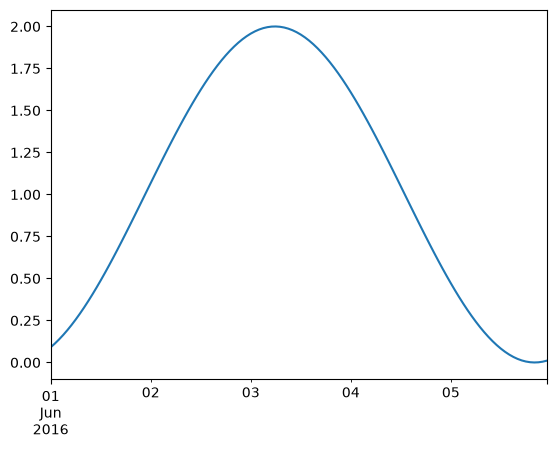

In [36]:
series = pd.Series(np.sin(np.linspace(2, 8, 120) * -1) + 1.0)
series.index = [pd.Timestamp("2016-06-01 00:00:00") + pd.Timedelta(hours=i) for i in range(120)]
series.plot()

Now we add the above sine function to a boundary node at RVW_01. 'Series' should be a Pandas-series with time stamps on the indices.

In [37]:
hydamo.external_forcings.add_boundary_condition(
    "RVW_01", (197464.0, 392130.0), "dischargebnd", series, fm.geometry.netfile.network
)

We might as well use a discharge boundary with a float, to use a constant value for discharge.

In [38]:
hydamo.external_forcings.add_boundary_condition(
    "RVW_04", (201215.456000, 392841.807000), "dischargebnd", 1.2, fm.geometry.netfile.network
)

Last option is a Q-H relation, a 'qhbnd'. Supply a dict-ojbect with Q and H keys and the values as list:

In [39]:
hydamo.external_forcings.add_boundary_condition(
    "RVW_03", (197478.865000, 393490.384000), "qhbnd", {'Q': [0,0.5,1,2,10], 'H':[22.1, 23.0, 24.0, 25.0]}, fm.geometry.netfile.network
)

In [40]:
hydamo.dict_to_dataframe(hydamo.external_forcings.boundary_nodes)

,id,quantity,vec1,vec2,unit1,unit2,nodeid
RVM_02,RVM_02,waterlevelbnd,None,11.0,minutes since 0000-00-00 00:00:00,m,201410.057000_396622.821000
RVW_01,RVW_01,dischargebnd,"[0.0, 60.0, 120.0, 180.0, 240.0, 300.0, 360.0,...","[0.09070257317431829, 0.11283143771052084, 0.1...",minutes since 2016-06-01 00:00:00,m3/s,197458.857019_392135.000000
RVW_04,RVW_04,dischargebnd,None,1.2,minutes since 0000-00-00 00:00:00,m3/s,201215.456000_392841.807000
RVW_03,RVW_03,qhbnd,"[0, 0.5, 1, 2, 10]","[22.1, 23.0, 24.0, 25.0]",m3/s,m,197478.865000_393490.384000


To obtain data for boundaries, it might be necessary to use other models' results. The following function retrieves a location and timeseries from a his_nc file. We just show it here for illustration. Input is a HIS_NC.file, type of location (weir, pump, bridge, culvert, uweir, observation_point), id of location, variable (waterlevel, discharge, waterlevel_upstream, waterlevel_downstream) and optionally a selection of the time series.

In [41]:
#  geom_bound, series_bound = hydamo.external_forcings.convert.timeseries_from_other_model(his_his_file, 'weir', 'S_96547', 'waterlevel_upstream', starttime=None, endtime=None)

In the same way as for boundaries, it is possible to add laterals using a fuction. Here are two examples. The first one adds a constant flow (1.5 m3/s) to a location on branch W_2399.0:

In [42]:
hydamo.external_forcings.add_lateral(id='LAT01', branchid='W_2399_0', chainage=100., discharge=1.5 )

The second example adds a timeseries, provided as a pandas series-object, to another location on the same branch.It can be read from CSV, but here we pass a hypothetical sine-function.

In [43]:
series = pd.Series(np.sin(np.linspace(2, 8, 120) * -1) + 2.0)
series.index = [pd.Timestamp("2016-06-01 00:00:00") + pd.Timedelta(hours=i) for i in range(120)]
hydamo.external_forcings.add_lateral(id='LAT02', branchid='W_2399_0', chainage=900., discharge=series )

### Initial conditions

Initial water levels or water depths for the 1D network can be specified in several ways:

1. **Uniform**: one water level or water depth for the whole network (`set_initial_waterlevel` / `set_initial_waterdepth`).
2. **From a shapefile**: a value per polygon, e.g. the target level (streefpeil) per level area. The polygons are written as polygon files (.pol), one per distinct value.
3. **From a model result**: values at the 1D nodes of an earlier model run (map- or fou-file). These are written as samples (xyz-file).
4. **Corrected model result**: a model result in which the values within some polygons are replaced, e.g. by the target level.

Options 2-4 use `set_spatial_field`, which supports three file types: `"polygon"` (default for polygons), `"raster"` (polygons rasterized to a GeoTIFF, mainly useful for 2D fields such as roughness) and `"sample"` (points).

Some things to keep in mind (tested with D-HYDRO 2026.02):

- Fields are applied in the order in which they are added; where they overlap, the last one wins.
- 1D nodes that get no value from any field keep the default water level from the MDU (`WaterLevIni`), which leaves them dry when it is below the bed level. Make sure all nodes are covered, e.g. by starting with a model result.
- A uniform water depth overrides spatial water levels, and a water depth field removes water levels set before it. Use one quantity, or add water depth fields before water level fields.
- `interpolationMethod=averaging` does not assign values to 1D nodes and is therefore refused for `locationtype="1d"`.

All fields are written to the initial field file (`fieldFile.ini`) when writing the model, see `models.write_initial_fields` below. In future D-Flow FM versions, spatial input will move to `[Spatial]` blocks in the external forcings file; this does not change the way the fields are defined here.

Choose one of the options below:

In [ ]:
# "uniform", "shapefile", "modelresult" or "corrected"
initial_condition = "shapefile"

# model result of an earlier run of this model. A fou-file is small and contains e.g. the maximum water level.
# A map-file can be used as well, e.g. with field "mesh1d_s1" and netcdf_index=-1 for the last time step.
model_result_file = data_path / "model_result" / "DFM_map_last.nc"

For the options with polygons, a layer with target levels per level area is needed. Normally this is read from a file, for example:

```python
peilgebieden = gpd.read_file(data_path / "peilgebieden.shp")
```

The sample data do not contain level areas, so here we use the catchments with a fictional target level:

In [45]:
peilgebieden = gpd.GeoDataFrame(hydamo.catchments[["code", "geometry"]].copy())
peilgebieden["streefpeil"] = 17.5
peilgebieden.iloc[10, peilgebieden.columns.get_loc("streefpeil")] = 16.5
peilgebieden.iloc[20, peilgebieden.columns.get_loc("streefpeil")] = 18.5

**Option 1: uniform.** Set a water depth of 1.5 m in the whole network. A uniform water level can be set with `set_initial_waterlevel`; use only one of the two.

In [46]:
if initial_condition == "uniform":
    hydamo.external_forcings.set_initial_waterdepth(1.5)
    # hydamo.external_forcings.set_initial_waterlevel(17.5)

**Option 2: from a shapefile.** Each polygon gets its value as a constant (`interpolationMethod=constant`). Polygons with the same value are written to one polygon file, with one block per value. Holes in polygons are not supported by polygon files. 1D nodes outside all polygons get no value, so in practice combine this with a field that covers all nodes (see option 4).

In [47]:
if initial_condition == "shapefile":
    hydamo.external_forcings.set_spatial_field(
        peilgebieden,
        "streefpeil",
        quantity="waterlevel",
        filename="initial_waterlevel.pol",
    )

**Option 3: from a model result.** `read_values_from_modelrun` reads a variable at the 1D nodes and returns points with a column `value`. Here the water level at the last time step from a reduced map-file is used. Since the points coincide with the 1D nodes of the same network, `triangulation` reproduces the values exactly at the nodes.

For an initial water depth, use for example the field `"mesh1d_s1"` and `quantity="waterlevel"` or `"mesh1d_waterdepth"` and `quantity="waterdepth"`.

In [48]:
if initial_condition in ["modelresult", "corrected"]:
    model_values = hydamo.external_forcings.read_values_from_modelrun(
        model_result_file, "mesh1d_s1",netcdf_index=-1,  crs=hydamo.catchments.crs
    )

if initial_condition == "modelresult":
    hydamo.external_forcings.set_spatial_field(
        model_values,
        "value",
        quantity="waterlevel",
        filename="initial_waterlevel.xyz",
        interpolationmethod="triangulation",
    )

**Option 4: corrected model result.** The model result is used as a basis, but within the selected polygons the values are replaced by the target level. Here we correct only the level areas with a deviating target level.

In [49]:
if initial_condition == "corrected":
    correction_polygons = peilgebieden[peilgebieden["streefpeil"] != 17.5]
    corrected_values = hydamo.external_forcings.correct_values_from_modelrun(
        model_values, correction_polygons, value_column="streefpeil"
    )
    print(f"{(corrected_values['value'] != model_values['value']).sum()} of {len(model_values)} values corrected.")

    hydamo.external_forcings.set_spatial_field(
        corrected_values,
        "value",
        quantity="waterlevel",
        filename="initial_waterlevel.xyz",
        interpolationmethod="triangulation",
    )

29 of 1421 values corrected.


Plot the model result and the corrected values:

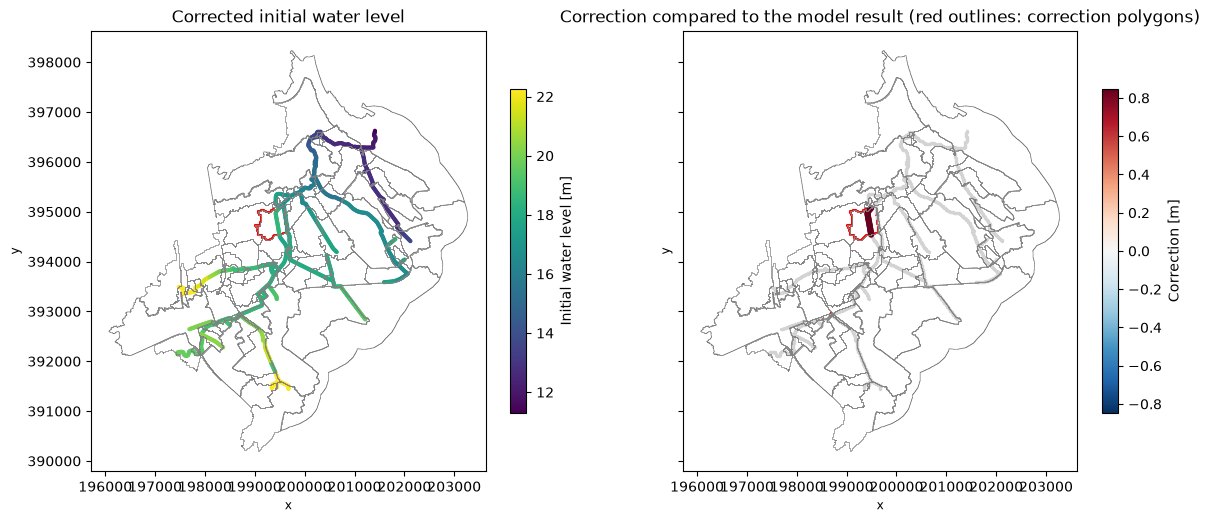

In [50]:
if initial_condition == "corrected":
    diff = corrected_values.assign(diff=corrected_values["value"] - model_values["value"])
    fig, axs = plt.subplots(1, 2, figsize=(14, 7), sharex=True, sharey=True)
    for ax in axs:
        peilgebieden.boundary.plot(ax=ax, color="grey", linewidth=0.5)
        correction_polygons.plot(ax=ax, facecolor="none", edgecolor="red", linewidth=1.5)
        ax.set_aspect("equal")
    corrected_values.plot(ax=axs[0], column="value", markersize=4, cmap="viridis", legend=True,
                          legend_kwds={"label": "Initial water level [m]", "shrink": 0.6})
    axs[0].set_title("Corrected initial water level")
    vmax = max(diff["diff"].abs().max(), 0.01)
    diff[diff["diff"] == 0].plot(ax=axs[1], color="lightgrey", markersize=2)
    diff[diff["diff"] != 0].plot(ax=axs[1], column="diff", markersize=12, cmap="RdBu_r", vmin=-vmax, vmax=vmax,
                                 legend=True, legend_kwds={"label": "Correction [m]", "shrink": 0.6})
    axs[1].set_title("Correction compared to the model result (red outlines: correction polygons)")

## 2D mesh

As explained above, several options exist for mesh generation.

1. Meshkernel (MK). This is eventually the preferred option: it is platform-independent, supports triangular meshes and has orthogenalization functionality. However, with certain input geometries issues occur.
2. Gridgeom (GG). Older functionality from delft3dfmpy. Only rectangular meshes are supported, but it is more stable and widely used.
3. Import a mesh from other software, such as SMS.

To generate a mesh we illustrate the following steps:
    - Generate grid within a polygon. The polygon is the extent given to the HyDAMO model.
    - Refine along the main branch
    - clip the mesh around the branches
    - Determine altitude from a DEM. 

<span style='color:Blue'> Important note: Triangular meshes are created without optimalization of smoothness or orthogonalization. This can be handled in de D-HYDRO GUI. In future we will implement this in D-HyDAMO.  </span>

In [51]:
if TwoD:    
    extent = gpd.read_file(data_path / "2D_extent.shp").at[0, "geometry"]
    network = fm.geometry.netfile.network
    cellsize=50.
    rasterpath = data_path / 'rasters/AHN_2m_clipped_filled.tif'

Add a rectangular mesh::

In [52]:
if TwoD:    
    mesh.mesh2d_add_rectilinear(network, extent, dx=cellsize, dy=cellsize)    

With MK, also the creation of a triangular mesh is possible. Note that there are maybe issues with the mesh orthogenality and additional steps in the D-Hydro GUI to orthogenalize the mesh may be necessary. In future we will implement this functionality in D-HyDAMO.

In [53]:
# if TwoD:
#     mesh.mesh2d_add_triangular(network, extent, edge_length=50.0)

Refine the 2D mesh within an arbitrary distance of 50 m from all branches (works on a subselection as well). There are several (optional) arguments to the refinement function, that typically give good results so it is not needed to pass them. For illustration, they are listed here. For more details, see https://deltares.github.io/MeshKernel. 

In [54]:
if TwoD:  
    refine_parameters = {
        'refine_intersected': True,
        'use_mass_center_when_refining': True,
        'min_edge_size': 1.0,
        'refinement_type': 2,
        'connect_hanging_nodes': True,
        'account_for_samples_outside_face': True,
        'max_refinement_iterations': 1,
        'smoothing_iterations': 5,
        'max_courant_time': 120.0,
        'directional_refinement': False
    }

In [55]:
if TwoD:
    buffer = Polygon(hydamo.branches.buffer(50.0).union_all().exterior)    
    print("Nodes before refinement:", network._mesh2d.mesh2d_node_x.size)        
    mesh.mesh2d_refine(network, buffer, 1, refine_parameters)
    print("Nodes after refinement:", network._mesh2d.mesh2d_node_x.size)           

Nodes before refinement: 7217
Nodes after refinement: 11622


Clip the 2D mesh in a 20m buffer around all branches. The algorithm is quite sensitive to the geometry, for example holes are not allowed.

In [56]:
if TwoD:    
    print("Nodes before clipping:", network._mesh2d.mesh2d_node_x.size)
    uitknippen = hydamo.branches.geometry.iloc[20:50].union_all().buffer(25.)       
    mesh.mesh2d_clip(network, uitknippen, deletemeshoption= DeleteMeshOption.FACES_WITH_INCLUDED_CIRCUMCENTERS)            
    print("Nodes after clipping:", network._mesh2d.mesh2d_node_x.size)           

Nodes before clipping: 11622
Nodes after clipping: 11166


Alternatively, the mesh can be read from a netcdf file (option 3):

In [57]:
# if TwoD:
#    mesh.mesh2d_from_netcdf(network, data_path / "import.nc")

Add elevation data to the cells

In [58]:
if TwoD:            
    mesh.mesh2d_altitude_from_raster(network, rasterpath, "face", "mean", fill_value=-999)
    

2026-10-20 12:07:31,021 - hydrolib.dhydamo.geometry.mesh - mesh - INFO - Creating GeoDataFrame of cell faces.


INFO:hydrolib.dhydamo.geometry.mesh:Creating GeoDataFrame of cell faces.


### Add 1d-2d links

Three options exist to add 1d2d links to the network:
 - from 1d to 2d
 - from 2d to 1d embedded: allowing overlap (i.e., the 2D cells and 1D branches are allowed to intersect)
 - from 2d to 1d lateral: there is no overlap and from each cell the closest 1d points are used. 
 
 See https://hkvconfluence.atlassian.net/wiki/spaces/DHYD/pages/601030709/1D2D-links for details.

In [59]:
if TwoD:         
    mesh.links1d2d_add_links_2d_to_1d_embedded(network)
    mesh.links1d2d_add_links_2d_to_1d_lateral(network, max_length=50.)        
    mesh.links1d2d_remove_1d_endpoints(network)
    mesh.links1d2d_remove_within(network, hydamo.branches.loc['W_1598_0'].geometry.buffer(100.))


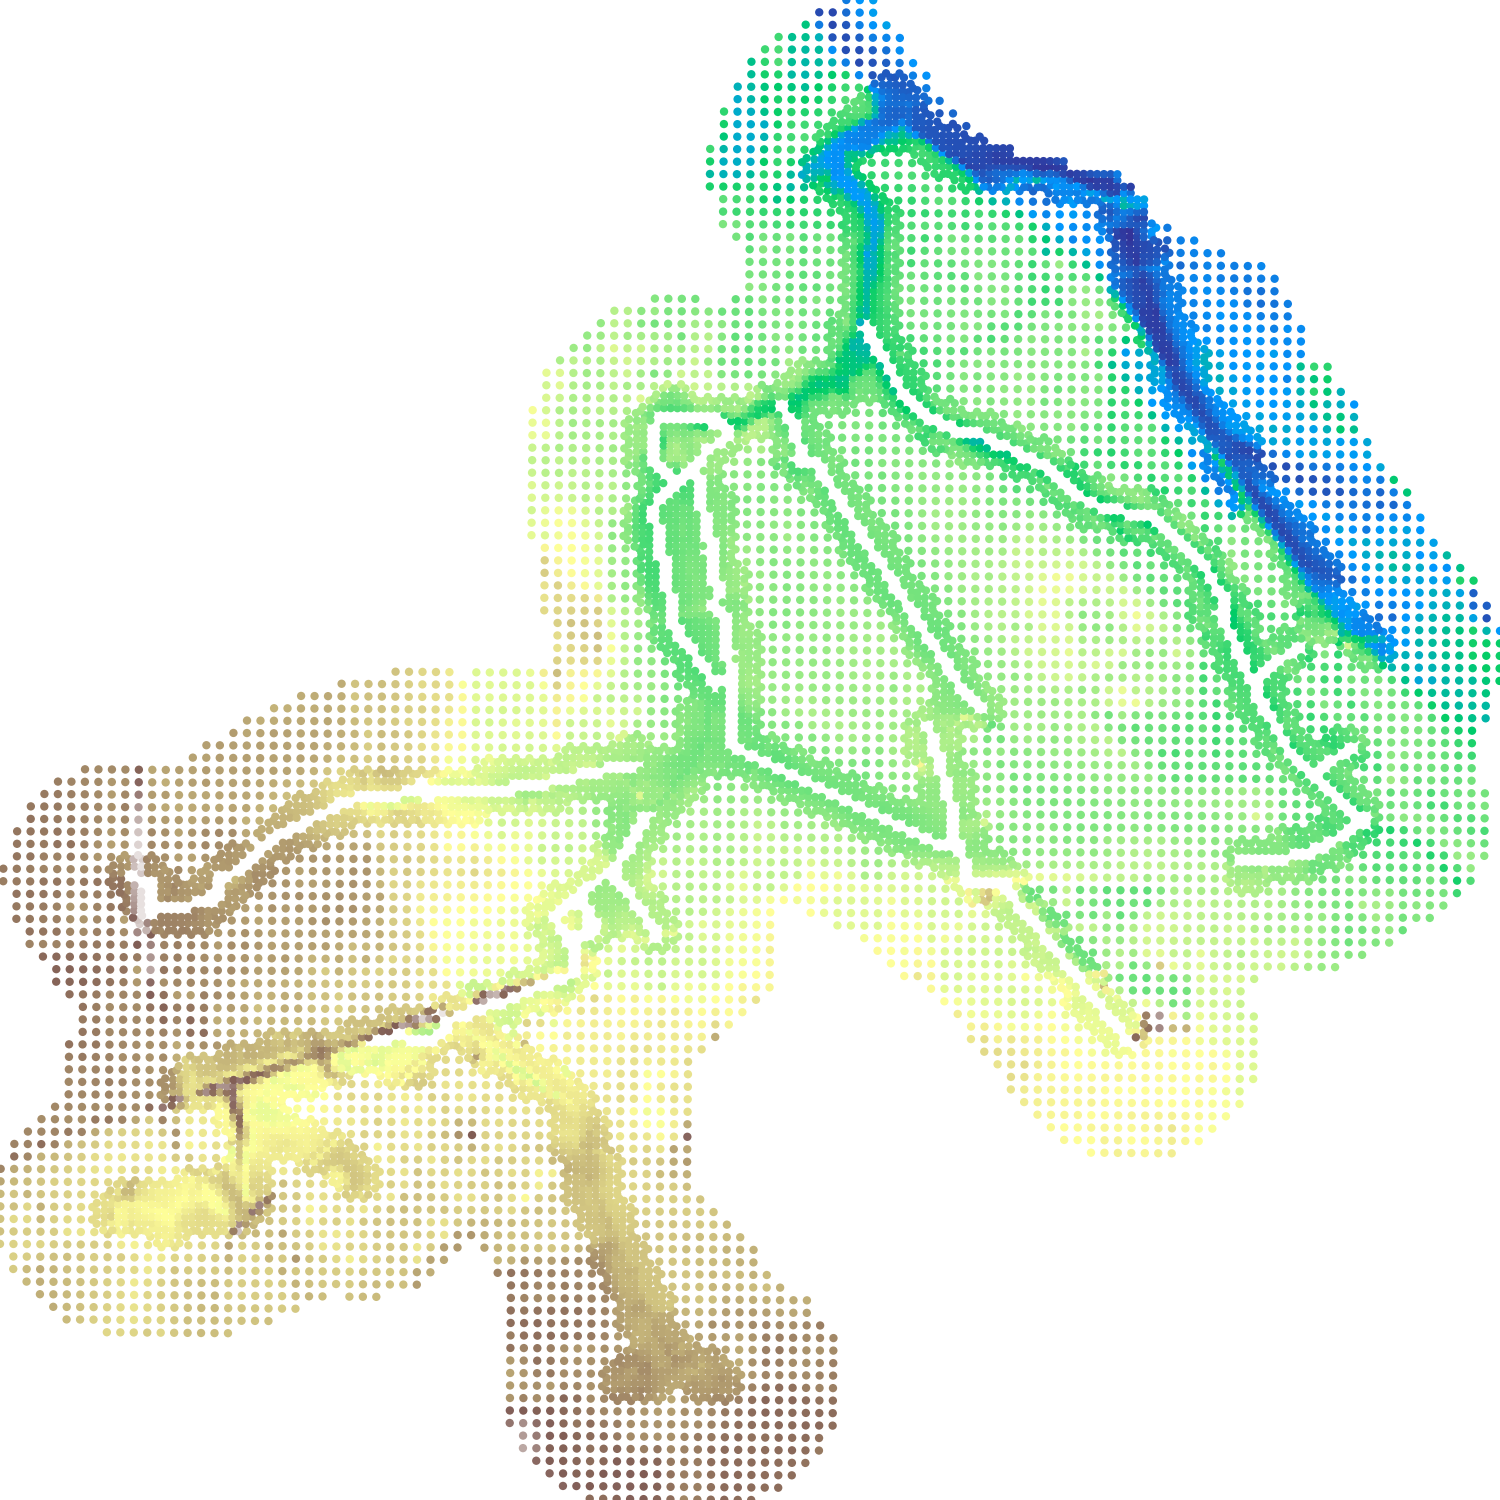

In [60]:
network = fm.geometry.netfile.network
m  = plot_network(network,face_z_kwargs={"cmap": 'terrain', "radius": 4.})
m

For finalizing the FM-model, we also need the coupling to the other modules. Therefore, we will do that first.

## RTC model

RTC contains many different options. These are now implemented in D-HyDAMO: 
- a PID controller (crest level is determined by water level or discharge at an observation point);
- an interval controller (idem, but with different options);
- a time controller (a time series of crest level is provided);
- the possibility for the users to provide their own XML-files for more complex cases. Depending on the complexity, the integration might not yet work for all cases.

First, initialize a DRTCModel-object. The input is hydamo (for the data), fm (for the time settings), a path where the model will be created (typically an 'rtc' subfolder), a timestep (default 60 seconds) and, optionally, a folder where the user can put 'custom' XML code that will be integrated in the RTC-model. These files will be parsed now and be integrated later.

These files can, for example, be obtained by sc

In [61]:


if RTC:
    if rtc_onlytimeseries:
        timeseries = pd.read_csv(rtc_timeseriesdata, sep=",", index_col='Time', parse_dates=True)
        drtcmodel = DRTCModel(
            hydamo,
            fm,
            output_path=output_path,
            rtc_timestep=60.0,
            rtc_onlytimeseries=True,
            rtc_timeseriesdata=timeseries
        )
    elif rtc_multiple_folders:
        drtcmodel = DRTCModel(
            hydamo,
            fm,
            output_path=output_path,
            rtc_timestep=60.0,
            complex_controllers_folder=[  # location where user defined XLM-code should be located
                data_path / "complex_controllers_1",
                data_path / "complex_controllers_2",
            ],
            id_limit_complex_controllers=["S_96684","S_96789", "ObsS_96684"],
        )
    else:
        drtcmodel = DRTCModel(
            hydamo,
            fm,
            output_path=output_path,
            rtc_timestep=60.0,
            complex_controllers_folder=data_path / "complex_controllers_1",  # location where user defined XLM-code should be located
            id_limit_complex_controllers=["S_96684", "ObsS_96684"],
        )


2026-10-20 12:07:42,833 - hydrolib.dhydamo.core.drtc - drtc - INFO - Complex controllers: found 4 unique structure references in dimr_config.xml: {'ObsS_96789', 'S_96789', 'ObsS_96684', 'S_96684'}


INFO:hydrolib.dhydamo.core.drtc:Complex controllers: found 4 unique structure references in dimr_config.xml: {'ObsS_96789', 'S_96789', 'ObsS_96684', 'S_96684'}


2026-10-20 12:07:42,838 - hydrolib.dhydamo.core.drtc - drtc - INFO - Complex controllers: matched 4 references to HyDAMO structures: {'ObsS_96789', 'S_96789', 'ObsS_96684', 'S_96684'}


INFO:hydrolib.dhydamo.core.drtc:Complex controllers: matched 4 references to HyDAMO structures: {'ObsS_96789', 'S_96789', 'ObsS_96684', 'S_96684'}


2026-10-20 12:07:42,842 - hydrolib.dhydamo.core.drtc - drtc - INFO - Complex controllers: applying id_limit_complex_controllers with 3 allowed IDs: {'S_96789', 'ObsS_96684', 'S_96684'}


INFO:hydrolib.dhydamo.core.drtc:Complex controllers: applying id_limit_complex_controllers with 3 allowed IDs: {'S_96789', 'ObsS_96684', 'S_96684'}


Making a proper whitelist (`id_limit_complex_controllers`) can be time-consuming for a large number of complex controllers. A helper method is available to return a list of unique IDs that are present in the provided xml folders and are validated against the present structures in the `HyDAMO` object. This code can be run independently from the `DRTCModel` initialisation. For example:

In [62]:

DRTCModel.find_complex_controller_ids( 
    [
        data_path / "complex_controllers_1", 
        data_path / "complex_controllers_2",
    ],
    hydamo,
)

{'S_96684', 'S_96789'}

If PID- or interval controllers are present, they need settings that are not included in the HyDAMO DAMO2.2 data. We define those in dictionaries. They can be specified for each structure - in that case the key of the dictionary should match the key in the HyDAMO DAMO2.2 'sturing'-object. If no separate settings are provided the 'global' settings are used.

Note that it is also possible to add RTC objects individually, in that case the settings should provided in the correct function as shown below. When interval controllers are converted from HyDAMO data, the settings above and below the deadband are taken from the min- and max setting.

In [63]:
if RTC and not rtc_onlytimeseries:
    pid_settings = {}
    interval_settings = {}
    
    pid_settings["global"] = {
        "ki": 0.001,
        "kp": 0.00,
        "kd": 0.0,
        "maxspeed": 0.00033,
    }
    interval_settings["global"] = {
        "deadband": 0.2,
        "maxspeed": 0.00033,
    }    
    pid_settings["kst_pid"] = {
            "ki": 0.001,
            "kp": 0.0,
            "kd": 0.0,
            "maxspeed": 0.00033,
        }

The function 'from_hydamo' converts the controllers that are specified in the HyDAMO DAMO2.2 data. The extra input consists of the settings for PID controllers (see above) and a dataframe with time series for the time controllers.

In [64]:
if RTC and not rtc_onlytimeseries:
    if not hydamo.management.typecontroller.empty:
        timeseries = pd.read_csv(data_path / "timecontrollers.csv")
        timeseries.index = timeseries.Time        

        drtcmodel.from_hydamo(pid_settings=pid_settings, interval_settings=interval_settings, timeseries=timeseries)


2026-10-20 12:07:43,135 - hydrolib.dhydamo.core.drtc - drtc - WARNING - nvt is not a valid controller type - skipped.


2026-10-20 12:07:43,145 - hydrolib.dhydamo.core.drtc - drtc - WARNING - nvt is not a valid controller type - skipped.


2026-10-20 12:07:43,151 - hydrolib.dhydamo.core.drtc - drtc - WARNING - Management for management_device {28d290f5-c1d2-48de-b687-38fa00e347d2} could not be connected to a culvert of a weir.


2026-10-20 12:07:43,160 - hydrolib.dhydamo.core.drtc - drtc - WARNING - nvt is not a valid controller type - skipped.


2026-10-20 12:07:43,164 - hydrolib.dhydamo.core.drtc - drtc - WARNING - Management for management_device {4a1d4f08-1174-4f68-b6d1-12b5781a9c73} could not be connected to a culvert of a weir.


2026-10-20 12:07:43,179 - hydrolib.dhydamo.core.drtc - drtc - WARNING - Management for management_device {4a1d4f08-1174-4f68-b6d1-12b5781a9c73} could not be connected to a culvert of a weir.


Additional controllers, that are not included in D-HyDAMO DAMO2.2 might be specified like this:

In [65]:
if RTC and not rtc_onlytimeseries:
    drtcmodel.add_time_controller(
        structure_id="S_96548", steering_variable="Crest level (s)", data=timeseries.loc[:,'S_96548']
    )

In [66]:
if RTC and not rtc_onlytimeseries:
    # construct a times series to use as a PID controller setpoint
    series = pd.Series(np.sin(np.linspace(2, 8, 120) * -1) + 13.0)
    series.index = [pd.Timestamp("2016-06-01 00:00:00") + pd.Timedelta(hours=i) for i in range(120)]
    drtcmodel.add_pid_controller(structure_id='S_96544', 
                                observation_location='ObsS_96544', 
                                steering_variable='Crest level (s)', 
                                target_variable='Water level (op)', 
                                setpoint=series,
                                ki = 0.001,
                                kp =0.,
                                kd =0,
                                max_speed = 0.00033,
                                upper_bound=13.4,
                                lower_bound=12.8,
                                interpolation_option = 'LINEAR',
                                extrapolation_option = "BLOCK"
                                )
    
    # define an interval controller with a constant setpoint for an orifice gate
    drtcmodel.add_interval_controller(structure_id='orifice_test', 
                                observation_location='ObsO_test', 
                                steering_variable='Gate lower edge level (s)', 
                                target_variable='Discharge (op)', 
                                setpoint=3.2,
                                setting_below=18.0,
                                setting_above=18.5,
                                max_speed=0.00033,
                                deadband=0.1,
                                interpolation_option = 'LINEAR',
                                extrapolation_option = "BLOCK"
                                )
    
    # and add a PID controller to a pump capacity
    drtcmodel.add_pid_controller(structure_id='113GIS', 
                                observation_location='ObsP_113GIS', 
                                steering_variable='Capacity (p)', 
                                target_variable='Water level (op)', 
                                setpoint=0.3,
                                ki = 0.001,
                                kp =0.,
                                kd =0,
                                max_speed = 0.00033,
                                upper_bound=0.4,
                                lower_bound=0.2
                                )
    
    # and add a PID controller to a culvert with a gate
    drtcmodel.add_pid_controller(structure_id='culvert_test', 
                                observation_location='ObsS_96684', 
                                steering_variable='Valve opening (s)', 
                                target_variable='Water level (op)', 
                                setpoint=16.5,
                                ki = 0.001,
                                kp =0.,
                                kd =0,
                                max_speed = 0.00033,
                                upper_bound=1.0,
                                lower_bound=0.1
                                )

## Rainfall runoff model

RR has not changed yet compared to delft3dfmpy. Initialize a model:

In [67]:
if RR:
    drrmodel = DRRModel()

Catchments are provided in the HyDAMO DAMO2.2 format and included in the GPKG. They can also be read from other formats using 'read_gml', or 'read_shp'. Note that in case of shapefiles column mapping is necessary because the column names are truncated. 

Note that when catchments have a "MultiPolygon' geometry, the multipolygons are 'exploded' into single polygon geometries. A warning of this is isued, and a suffix is added to every polygons ID to prevent duplicates. 

For every catchment, the land use areas will be calculated and if appopriate a maximum of four RR-nodes will be created per catchment:
 - unpaved (based on the Ernst concept)
 - paved 
 - greenhouse
 - open water (not the full Sobek2 open water, but only used to transfer (net) precipitation that falls on open water that is schematized in RR to the 1D/2D network.
 
At the moment, two options exist for the schematisation of the paved area:
 1) simple: the paved fraction of each catchment is modelled with a paved node, directly connected to catchments' boundary node
 <br>
 2) more complex: sewer area polygons and overflow points are used a input as well. For each sewer area, the overlapping paved area is the distributed over the overflows that are associated with the sewerarea (the column 'lateraleknoopcode') using the area fraction (column 'fractie') for each overflow. In each catchment, paved area that does not intersect with a sewer area gets an unpaved node as in option (1). <br>

Similar to sewer areas, additional greenhouse polygons and the corresponding laterals can be added to the model. For example, when these areas and their inflow locations are exactly known. 

Load data and settings. RR-parameters can be derived from a raster (using zonal statistics per catchment), or provided as a standard number. Rasters can be in any format that is accepted by the package rasterio: https://gdal.org/drivers/raster/index.html. All common GIS-formats (.asc, .tif) are accepted.

In [68]:
if RR:
    lu_file = data_path / "rasters" / "sobek_landuse.tif"
    ahn_file = data_path / "rasters" / "AHN_2m_clipped_filled.tif"
    soil_file = data_path / "rasters" / "sobek_soil.tif"
    surface_storage = 10.0 # [mm]
    infiltration_capacity = 100.0 # [mm/hr]
    initial_gwd = 1.2  # water level depth below surface [m]  
    runoff_resistance = 0.5 # [d]
    infil_resistance = 300.0 # [d]
    layer_depths = [0.0, 1.0, 2.0] # [m]
    layer_resistances = [30, 200, 10000] # [d]

A different meteo-station can be assigned to each catchment, of a different shape can be provided. Here, 'meteo_areas' are assumed equal to the catchments.

In [69]:
if RR:
    meteo_areas = hydamo.catchments 

### Configuration of greenhouse_areas

Similar to sewage areas and overflows for paved nodes, known greenhouse areas and greenhouse discharge locations can be assigned. Two extra shapefiles or geopackage layers are needed:
- contains polygons with greenhouse areas, with a column 'code' containing the ID. They are read into the object 'greenhouse_areas'. These areas are converted to greenhouse nodes irrespective of the underlying landuse in the landuse raster;
- greenhouse outflow points: with a column 'codegerelateerdobject' to couple it with the right polygon. They are read into the object 'greenhouse_laterals';
  
By adding columns to greenhouse_areas their parameters can be specified: roof_storage_mm is the storage on the roof, basin_storage_class is the above-ground storageclass that is used in D-RR. It discreminates in 10 classes each with different basin storage capacities (in m3/ha).  If no specific numbers per greenhouse provided per greenhouse_are provided uniform values can be provided.

These storage classes identified by 'basin_storage_class' are as follows:
 1. 0-500 m3/ha;
 2. 500-1000 m3/ha;
 3. 1000-1500 m3/ha;
 4. 1500-2000 m3/ha;
 5. 2000-2500 m3/ha;
 6. 2500-3000 m3/ha;
 7. 3000-4000 m3/ha;
 8. 4000-5000 m3/ha;
 9. 5000-6000 m3/ha;
10. more than 600 m3/ha.

In [70]:
if RR:
    roof_storage = 5.0 # [mm]
    basin_storage_class = 3# default class
    hydamo.greenhouse_areas.read_gpkg_layer( data_path / 'greenhouses.gpkg', layer_name='greenhouses', index_col='code')
    hydamo.greenhouse_laterals.read_gpkg_layer(data_path / 'greenhouse_laterals.gpkg', layer_name='laterals')
    hydamo.greenhouse_laterals.snap_to_branch(hydamo.branches, snap_method="overal", maxdist=1100)
    hydamo.greenhouse_areas['roof_storage_mm'] = roof_storage 
    hydamo.greenhouse_areas['basin_storage_class'] = [i+1 for i in range(hydamo.greenhouse_areas.shape[0])]

2026-10-20 12:07:43,442 - hydrolib.dhydamo.geometry.spatial - spatial - INFO - Centroid for lat_kas_2 at x=198444.5516 and y=393828.3753 has 22 branches with maxdist=1100 and method=overal, chosing closest branch W_2378_0


INFO:hydrolib.dhydamo.geometry.spatial:Centroid for lat_kas_2 at x=198444.5516 and y=393828.3753 has 22 branches with maxdist=1100 and method=overal, chosing closest branch W_2378_0


2026-10-20 12:07:43,445 - hydrolib.dhydamo.geometry.spatial - spatial - INFO - Centroid for lat_kas_3 at x=198190.6935 and y=393755.0385 has 19 branches with maxdist=1100 and method=overal, chosing closest branch W_2378_0


INFO:hydrolib.dhydamo.geometry.spatial:Centroid for lat_kas_3 at x=198190.6935 and y=393755.0385 has 19 branches with maxdist=1100 and method=overal, chosing closest branch W_2378_0


2026-10-20 12:07:43,450 - hydrolib.dhydamo.geometry.spatial - spatial - INFO - Centroid for lat_kas_4 at x=197998.8896 and y=393676.0604 has 14 branches with maxdist=1100 and method=overal, chosing closest branch W_2378_0


INFO:hydrolib.dhydamo.geometry.spatial:Centroid for lat_kas_4 at x=197998.8896 and y=393676.0604 has 14 branches with maxdist=1100 and method=overal, chosing closest branch W_2378_0


2026-10-20 12:07:43,455 - hydrolib.dhydamo.geometry.spatial - spatial - INFO - Centroid for lat_kas_5 at x=199455.9350 and y=394748.4159 has 22 branches with maxdist=1100 and method=overal, chosing closest branch W_242218_0


INFO:hydrolib.dhydamo.geometry.spatial:Centroid for lat_kas_5 at x=199455.9350 and y=394748.4159 has 22 branches with maxdist=1100 and method=overal, chosing closest branch W_242218_0


2026-10-20 12:07:43,462 - hydrolib.dhydamo.geometry.spatial - spatial - INFO - Centroid for lat_kas_6 at x=198761.0453 and y=393844.2097 has 26 branches with maxdist=1100 and method=overal, chosing closest branch W_2378_0


INFO:hydrolib.dhydamo.geometry.spatial:Centroid for lat_kas_6 at x=198761.0453 and y=393844.2097 has 26 branches with maxdist=1100 and method=overal, chosing closest branch W_2378_0


In [71]:
hydamo.greenhouse_areas.head()

,code,geometry,roof_storage_mm,basin_storage_class
code,,,,
kas_2,kas_2,"POLYGON ((197711.889 394630.849, 197734.454 39...",5.0,1
kas_3,kas_3,"POLYGON ((197826.125 394523.664, 197862.793 39...",5.0,2
kas_4,kas_4,"POLYGON ((197718.941 394691.493, 197864.204 39...",5.0,3
kas_5,kas_5,"POLYGON ((199205.914 394791.338, 199307.854 39...",5.0,4
kas_6,kas_6,"POLYGON ((198676.145 393974.959, 198829.07 393...",5.0,5


### Unpaved nodes

For land use and soil type a coding is prescribed. For landuse, the legend of the map is expected to be as follows: <br>
 1 potatoes  <br>
 2 wheat<br>
 3 sugar beet<br> 
 4 corn       <br> 
 5 other crops <br> 
 6 bulbous plants<br> 
 7 orchard<br>
 8 grass  <br>
 9 deciduous forest  <br>
10 coniferous forest<br>
11 nature<br>
12 barren<br>
13 open water<br>
14 built-up<br>
15 greenhouses<br>

For classes 1-12, the areas are calculated from the provided raster and remapped to the classification in the Sobek RR-tables.


The coding for the soil types:<br>
1 'Veengrond met veraarde bovengrond'<br>
 2 'Veengrond met veraarde bovengrond, zand'<br>
 3 'Veengrond met kleidek'<br>
 4 'Veengrond met kleidek op zand'<br>
 5 'Veengrond met zanddek op zand'<br>
 6 'Veengrond op ongerijpte klei'<br>
 7 'Stuifzand'<br>
 8 'Podzol (Leemarm, fijn zand)'<br>
 9 'Podzol (zwak lemig, fijn zand)'<br>
10 'Podzol (zwak lemig, fijn zand op grof zand)'<br>
11 'Podzol (lemig keileem)'<br>
12 'Enkeerd (zwak lemig, fijn zand)'<br>
13 'Beekeerd (lemig fijn zand)'<br>
14 'Podzol (grof zand)'<br>
15 'Zavel'<br>
16 'Lichte klei'<br>
17 'Zware klei'<br>
18 'Klei op veen'<br>
19 'Klei op zand'<br>
20 'Klei op grof zand'<br>
21 'Leem'<br>


And surface elevation needs to be in m+NAP.

Unpaved_from_input has now an optional argument containing the greenhouse areas: if a catchment intersects them its area (the most ocurring class) is corrected for the greenhouse area. 

In [72]:
if RR:
    drrmodel.unpaved.io.unpaved_from_input(
        hydamo.catchments,
        lu_file,
        ahn_file,
        soil_file,
        surface_storage,
        infiltration_capacity,
        initial_gwd,
        meteo_areas,
        greenhouse_areas=hydamo.greenhouse_areas,

    )
    drrmodel.unpaved.io.ernst_from_input(
        hydamo.catchments,
        depths=layer_depths,
        resistance=layer_resistances,
        infiltration_resistance=infil_resistance,
        runoff_resistance=runoff_resistance,
    )    

2026-10-20 12:07:46,814 - hydrolib.dhydamo.io.drrreader - drrreader - INFO - Catchment 77.0: subtracting 8175.7679414670165 m2 from class 1 for supplied greenhouse area.


INFO:hydrolib.dhydamo.io.drrreader:Catchment 77.0: subtracting 8175.7679414670165 m2 from class 1 for supplied greenhouse area.


2026-10-20 12:07:47,008 - hydrolib.dhydamo.io.drrreader - drrreader - INFO - Catchment 306.0: subtracting 6275.516458552291 m2 from class 2 for supplied greenhouse area.


INFO:hydrolib.dhydamo.io.drrreader:Catchment 306.0: subtracting 6275.516458552291 m2 from class 2 for supplied greenhouse area.


2026-10-20 12:07:47,018 - hydrolib.dhydamo.io.drrreader - drrreader - INFO - Catchment 309.0: subtracting 6900.172632087566 m2 from class 4 for supplied greenhouse area.


INFO:hydrolib.dhydamo.io.drrreader:Catchment 309.0: subtracting 6900.172632087566 m2 from class 4 for supplied greenhouse area.


### Paved nodes

Default parameter values for paved nodes. There are three options to give a sewage properies: (pump-overcapacity and sewer storage):
1. a default value in mm/h that will be used for every paved node and converted to m3/s;
2. a raster with values in mm/h. For each paved node zonal statistics will be used to extract to correct value that will be converted to m3/s;
3. as attributes to the sewer areas, where each area will have a storage in mm and POC in m3/s. The pump capacity will be divided over the related overflows.


In [73]:
if RR:    
    street_storage = 5.0 # [mm]
    sewer_storage = 5.0 # [mm]
    poc_mmh  = data_path / 'rasters/pumpcap.tif'  # in mm/h, or using a constant: poc_mmh = 0.7 #  [mm/h]

For paved areas, two options are allowed.
1) simply assign a paved noded to the catchment area that is paved in the landuse map.

In [74]:
# if RR:
#     drrmodel.paved.io.paved_from_input(
#             catchments=hydamo.catchments,
#             landuse=lu_file,
#             surface_level=ahn_file,
#             street_storage=street_storage,
#             sewer_storage=sewer_storage,
#             pump_capacity=pumpcapacity,
#             meteo_areas=meteo_areas,
#             zonalstats_alltouched=True,
#         )


 2. Also use sewer-areas and overflows by providing them to the function. In that case, the 'overflows' shapefile should have a field 'codegerelateerdobject' that contains the 'code' of the sewer area it is linked to, and a 'fraction' (float) that contains the fraction of the sewer area that drains through that overflow. 

For every overflow, a paved node is created, containing the fraction of the sewer area. The paved area of the catchment that intersects the sewer-area is corrected for this; for the remaining paved area a seperate paved node is created.

If sewer areas contain POC and storage values, the fields are mapped to 'riool_berging_mm' and 'riool_poc_m3s'.

In [75]:
if RR:
    hydamo.sewer_areas.read_shp(str(data_path / 'rioleringsgebieden.shp'), index_col='code', column_mapping={'Code':'code', 'Berging_mm':'riool_berging_mm', 'POC_m3s':'riool_poc_m3s' })
    hydamo.overflows.read_shp(str(data_path / 'overstorten.shp'), column_mapping={'codegerela': 'codegerelateerdobject'})
    hydamo.overflows.snap_to_branch(hydamo.branches, snap_method="overal", maxdist=1100)

2026-10-20 12:07:47,512 - hydrolib.dhydamo.geometry.spatial - spatial - INFO - Centroid for MW1072B at x=201147.0000 and y=396171.9000 has 11 branches with maxdist=1100 and method=overal, chosing closest branch W_2591_0


INFO:hydrolib.dhydamo.geometry.spatial:Centroid for MW1072B at x=201147.0000 and y=396171.9000 has 11 branches with maxdist=1100 and method=overal, chosing closest branch W_2591_0


2026-10-20 12:07:47,527 - hydrolib.dhydamo.geometry.spatial - spatial - INFO - Centroid for BBB_de_Kuyper at x=202171.1000 and y=394462.3000 has 6 branches with maxdist=1100 and method=overal, chosing closest branch W_2591_1


INFO:hydrolib.dhydamo.geometry.spatial:Centroid for BBB_de_Kuyper at x=202171.1000 and y=394462.3000 has 6 branches with maxdist=1100 and method=overal, chosing closest branch W_2591_1


2026-10-20 12:07:47,536 - hydrolib.dhydamo.geometry.spatial - spatial - INFO - Centroid for 6134D.9 at x=199077.0000 and y=393377.0000 has 28 branches with maxdist=1100 and method=overal, chosing closest branch W_2678_0


...

INFO:hydrolib.dhydamo.geometry.spatial:Centroid for B2 at x=198269.5215 and y=392443.9941 has 16 branches with maxdist=1100 and method=overal, chosing closest branch W_242465_0


2026-10-20 12:07:47,640 - hydrolib.dhydamo.geometry.spatial - spatial - INFO - Centroid for B3 at x=198560.4083 and y=392730.1523 has 21 branches with maxdist=1100 and method=overal, chosing closest branch W_242460_0


INFO:hydrolib.dhydamo.geometry.spatial:Centroid for B3 at x=198560.4083 and y=392730.1523 has 21 branches with maxdist=1100 and method=overal, chosing closest branch W_242460_0


2026-10-20 12:07:47,655 - hydrolib.dhydamo.geometry.spatial - spatial - INFO - Centroid for B4 at x=199012.5812 and y=392280.3418 has 20 branches with maxdist=1100 and method=overal, chosing closest branch W_2645_0


INFO:hydrolib.dhydamo.geometry.spatial:Centroid for B4 at x=199012.5812 and y=392280.3418 has 20 branches with maxdist=1100 and method=overal, chosing closest branch W_2645_0


In [76]:
if RR:
     drrmodel.paved.io.paved_from_input(
            catchments=hydamo.catchments,
            landuse=lu_file,
            surface_level=ahn_file,
            sewer_areas=hydamo.sewer_areas,
            overflows=hydamo.overflows,
            street_storage=street_storage,
            sewer_storage=sewer_storage,
            pump_capacity=poc_mmh,
            meteo_areas=meteo_areas,
            zonalstats_alltouched=True,
        )

2026-10-20 12:07:51,327 - hydrolib.dhydamo.io.drrreader - drrreader - INFO - No paved area outside sewer area in catchments 71.0.


INFO:hydrolib.dhydamo.io.drrreader:No paved area outside sewer area in catchments 71.0.


2026-10-20 12:07:53,664 - hydrolib.dhydamo.io.drrreader - drrreader - INFO - No paved area outside sewer area in catchments 298.0.


INFO:hydrolib.dhydamo.io.drrreader:No paved area outside sewer area in catchments 298.0.


2026-10-20 12:07:53,970 - hydrolib.dhydamo.io.drrreader - drrreader - INFO - No paved area outside sewer area in catchments 307.0.


INFO:hydrolib.dhydamo.io.drrreader:No paved area outside sewer area in catchments 307.0.


2026-10-20 12:07:54,791 - hydrolib.dhydamo.io.drrreader - drrreader - INFO - No paved area outside sewer area in catchments 432.0.


INFO:hydrolib.dhydamo.io.drrreader:No paved area outside sewer area in catchments 432.0.


### Greenhouse nodes

Also for greenhouses two options exist. <br>
Option 1: use both the land use map and supply separate greenhouse areas and laterals. 

In [77]:
if RR:
    # greenhouse with additional greenhouse nodes
    drrmodel.greenhouse.io.greenhouse_from_input(
            catchments=hydamo.catchments,
            landuse=lu_file,
            surface_level=ahn_file,
            greenhouse_areas=hydamo.greenhouse_areas,
            greenhouse_laterals=hydamo.greenhouse_laterals,
            roof_storage=roof_storage,
            basin_storage_class=basin_storage_class,
            meteo_areas=meteo_areas,
            zonalstats_alltouched=True            
        )

2026-10-20 12:07:58,376 - hydrolib.dhydamo.io.drrreader - drrreader - INFO - Catchment: 309.0: subtracting 1325.0 m2 from greenhouse area in landuse map.


INFO:hydrolib.dhydamo.io.drrreader:Catchment: 309.0: subtracting 1325.0 m2 from greenhouse area in landuse map.


Option 2: base greenhouse areas only on the land use map.

In [78]:
# if RR:
#     drrmodel.greenhouse.io.greenhouse_from_input(
#         hydamo.catchments, lu_file, ahn_file, roof_storage, meteo_areas, zonalstats_alltouched=True
#     )

### Open water

As opposed to Sobek, in D-Hydro open water is merely an interface for precpitation and evaporation. No management and water levels are included.

In [79]:
# RR
if RR:
    drrmodel.openwater.io.openwater_from_input(
        hydamo.catchments, lu_file, meteo_areas, zonalstats_alltouched=True
    )

### RR boundaries

They are different for the (paved) case with and without overflows. Overflows and greenhouse laterals are optional, but should be provided if they have been used above. 

In [80]:
if RR:
    drrmodel.external_forcings.io.boundary_from_input(hydamo.laterals, hydamo.catchments, drrmodel, overflows=hydamo.overflows, greenhouse_laterals=hydamo.greenhouse_laterals)

2026-10-20 12:07:59,997 - hydrolib.dhydamo.io.drrreader - drrreader - INFO - Adding overflows to the boundary nodes.


INFO:hydrolib.dhydamo.io.drrreader:Adding overflows to the boundary nodes.


2026-10-20 12:08:00,011 - hydrolib.dhydamo.io.drrreader - drrreader - INFO - Adding greenhouse_laterals to the boundary nodes.


INFO:hydrolib.dhydamo.io.drrreader:Adding greenhouse_laterals to the boundary nodes.


### External forcings

Three types of external forcing need to be provided:<br>
- Seepage/drainage
- Precipitation
- Evaporation

All are assumed to be spatially variable and thus need to pe provided as rasters per time step. Only the locations of the folders containing the rasters need to be provided; the time step is then derived from the file names.

Precipitation and evaporation are assumed to be in mm/d. As for evaporation only one meteostation is used, the meteo_areas are dissolved. For seepage, as the use of Metaswap-rasters is allowed, the unit is assumed to m3/grid cell/timestep.

Rastertypes can be any type that is recognized by rasterio (in any case Geotiff and ArcASCII rasters). If the file extension is 'IDF', as is the case in Modflow output, the raster is read using the 'imod'-package.

IMPORTANT: time steps are extracted from the file names. Therefore, the names should cohere to some conditions:
The filename should consist of at least two parts, separated by underscores. The second part needs to contain time information, which should be formatted as YYYYMMDDHHMMSS (SS may be omitted). Or, for daily data YYYYMMDD.

For example: 'precip_20200605151500.tif'

Extracting meteo-data from rasters can be time consuming. If precip_file and evap_file are specified, meteo-files are copied from an existing location.

In [81]:
if RR:
    seepage_folder = data_path / "rasters" / "seepage"
    precip_file = str(data_path / "DEFAULT.BUI")
    evap_folder = data_path / "rasters" / "evaporation"
    drrmodel.external_forcings.io.seepage_from_input(hydamo.catchments, seepage_folder)
    drrmodel.external_forcings.io.precip_from_input(meteo_areas, precip_folder=None, precip_file=precip_file)
    drrmodel.external_forcings.io.evap_from_input(meteo_areas, evap_folder=evap_folder, evap_file=None)

Reading seepage files:   0%|          | 0/3 [00:00<?, ?it/s]

Reading evaporation files:   0%|          | 0/3 [00:00<?, ?it/s]

Add the main parameters:

In [82]:
if RR:   
    drrmodel.d3b_parameters["Timestepsize"] = 300
    drrmodel.d3b_parameters["StartTime"] = "'2016/06/01;00:00:00'"  # should be equal to refdate for D-HYDRO
    drrmodel.d3b_parameters["EndTime"] = "'2016/06/03;00:00:00'"
    drrmodel.d3b_parameters["RestartIn"] = 0
    drrmodel.d3b_parameters["RestartOut"] = 0
    drrmodel.d3b_parameters["RestartFileNamePrefix"] = "Test"
    drrmodel.d3b_parameters["UnsaturatedZone"] = 1
    drrmodel.d3b_parameters["UnpavedPercolationLikeSobek213"] = -1
    drrmodel.d3b_parameters["VolumeCheckFactorToCF"] = 100000


Laterals are different for the case with and without RR. There can be three options:
1) laterals from the RR model (RR=True). There will be real-time coupling where RR and FM are calculated in parallel. Note that, again, the overflows are needed because there are extra boundaries. If there are no overflows, it does not have to be provided.
2) timeseries: lateral_discharges can be a dataframe with the code of the lateral as column headers and timesteps as index
3) constant: lateral_discharges can be a pandas Series with the code of the lateral as the index. This is the case in the example when RR=False.

In [83]:
if RR:
    hydamo.external_forcings.convert.laterals(
        hydamo.laterals,
        overflows=hydamo.overflows,
        greenhouse_laterals=hydamo.greenhouse_laterals,
        lateral_discharges=None,
        rr_boundaries=drrmodel.external_forcings.boundary_nodes
    )
else:
    lateral_discharges = hydamo.laterals["afvoer"]
    lateral_discharges.index = hydamo.laterals.code
    hydamo.external_forcings.convert.laterals(
        hydamo.laterals, lateral_discharges=lateral_discharges, rr_boundaries=None
    )


### Plot the RR model

In [84]:
def node_geometry(dict):
    # Function to put the node geometries in geodataframes
    from shapely.geometry import LineString, Point

    geoms = []
    links = []
    for i in dict.items():
        if "ar" in i[1]:
            if np.sum([float(s) for s in i[1]["ar"].split(" ")]) > 0:
                geoms.append(Point((float(i[1]["px"]), float(i[1]["py"]))))
                links.append(
                    LineString(
                        (
                            Point(float(i[1]["px"]), float(i[1]["py"])),
                            Point(
                                float(drrmodel.external_forcings.boundary_nodes[i[1]["boundary_node"]]["px"]),
                                float(drrmodel.external_forcings.boundary_nodes[i[1]["boundary_node"]]["py"]),
                            ),
                        )
                    )
                )
        else:
            geoms.append(Point((float(i[1]["px"]), float(i[1]["py"]))))
    return ((gpd.GeoDataFrame(geoms, columns=["geometry"],crs=28992)), gpd.GeoDataFrame(links, columns=["geometry"], crs=28992))

In [85]:
# Map extent
clip_gs = gpd.GeoSeries([hydamo.clipgeo], crs=28992).to_crs(4326)
b = clip_gs.total_bounds

m = folium.Map(tiles="OpenStreetMap", width=1000)
m.fit_bounds([[b[1], b[0]], [b[3], b[2]]])

# Pre-compute node geometries once
unpaved_nodes,    unpaved_links    = node_geometry(drrmodel.unpaved.unp_nodes)
paved_nodes,      paved_links      = node_geometry(drrmodel.paved.pav_nodes)
greenhouse_nodes, greenhouse_links = node_geometry(drrmodel.greenhouse.gh_nodes)
openwater_nodes,  openwater_links  = node_geometry(drrmodel.openwater.ow_nodes)
boundary_nodes,   _                = node_geometry(drrmodel.external_forcings.boundary_nodes)

# --- helpers ---
def point_layer(gdf, name, color, symbol, size=14):
    fg = folium.FeatureGroup(name=name)
    for _, row in gdf.to_crs(4326).iterrows():
        pt = row.geometry if row.geometry.geom_type == "Point" else row.geometry.centroid
        folium.Marker(
            location=[pt.y, pt.x],
            icon=folium.DivIcon(
                html=f'<span style="font-size:{size}px;color:{color};line-height:1;">{symbol}</span>',
                icon_size=(size, size),
                icon_anchor=(size // 2, size // 2),
            ),
            tooltip=name,
        ).add_to(fg)
    fg.add_to(m)

# --- layers (bottom to top) ---

# Catchments
folium.GeoJson(
    hydamo.catchments.geometry.set_crs(28992).to_crs(4326),
    name="Catchments",
    style_function=lambda _: {
        "fillColor": "pink", "color": "black",
        "weight": 1, "fillOpacity": 0.5,
    },
).add_to(m)

# Branches
folium.GeoJson(
    hydamo.branches.geometry.set_crs(28992).to_crs(4326),
    name="Channel",
    style_function=lambda _: {"color": "#1f77b4", "weight": 2},
).add_to(m)

# RR links (all grouped, black thin lines)
rr_links = folium.FeatureGroup(name="RR-link")
for links in [unpaved_links, paved_links, greenhouse_links, openwater_links]:
    folium.GeoJson(
        links.to_crs(4326),
        style_function=lambda _: {"color": "black", "weight": 1, "opacity": 0.6},
    ).add_to(rr_links)
rr_links.add_to(m)

# Node point layers
point_layer(unpaved_nodes,    "Unpaved",     "green",  "\u25a0", size=14)
point_layer(paved_nodes,      "Paved",       "red",    "\u25a0", size=12)
point_layer(greenhouse_nodes, "Greenhouse",  "yellow", "\u25cf", size=12)
point_layer(openwater_nodes,  "Openwater",   "blue",   "\u25cf", size=10)
point_layer(boundary_nodes,   "RR Boundary", "purple", "\u25cf", size=12)

folium.LayerControl().add_to(m)
m

## Writing the model

Now we call Hydrolib-core functionality to write the model. First, we initialize an object that converts all dataframes to Hydrolib-core objects. Then we add these models to the file structure of the FM model.

Call a function to convert the dataframes to Hydrolib-core classes:

In [86]:
models = Df2HydrolibModel(hydamo, assign_default_profiles=True)

2026-10-20 12:08:08,680 - hydrolib.dhydamo.converters.df2hydrolibmodel - df2hydrolibmodel - INFO - Adding default cross section definition to branches with ids: W_1386_0, W_1698_0, W_1707_0, W_1944_0, W_2279_0, W_2352_0, W_2354_0, W_242216_0, W_242219_0, W_242465_0, W_242466_0, W_2645_0


INFO:hydrolib.dhydamo.converters.df2hydrolibmodel:Adding default cross section definition to branches with ids: W_1386_0, W_1698_0, W_1707_0, W_1944_0, W_2279_0, W_2352_0, W_2354_0, W_242216_0, W_242219_0, W_242465_0, W_242466_0, W_2645_0


And add the classes to the file structure. Each class requires a different approach, and at the moment Hydrolib-core is still in development. The code below is subject to change in future releases.

In [87]:
fm.geometry.structurefile = [StructureModel(structure=models.structures)]
fm.geometry.crosslocfile = CrossLocModel(crosssection=models.crosslocs)
fm.geometry.crossdeffile = CrossDefModel(definition=models.crossdefs)
fm.geometry.storagenodefile = StorageNodeModel(storagenode=models.storagenodes)

fm.geometry.frictfile = []
for i, fric_def in enumerate(models.friction_defs):
    fric_model = FrictionModel(global_=fric_def)
    fric_model.filepath = f"roughness_{i}.ini"
    fm.geometry.frictfile.append(fric_model)

if hasattr(hydamo.observationpoints, 'observation_points'):
    fm.output.obsfile = [ObservationPointModel(observationpoint=models.obspoints)]

extmodel = ExtModel()
# HYDROLIB-core writes ext file version 3.00 by default, which D-HYDRO Suite 2026.02 cannot read yet.
# Version 2.02 is sufficient for the [Boundary] and [Lateral] blocks used here.
extmodel.general.fileversion = "2.02"
extmodel.boundary = models.boundaries_ext
extmodel.lateral = models.laterals_ext
fm.external_forcing.extforcefilenew = extmodel

# initial conditions: writes the uniform values (1dField), rasters and samples to the fm-folder,
# and links them in the initial field file with relative paths
models.write_initial_fields(fm, output_path / "dflowfm")

IniFieldModel(filepath=None, serializer_config=INISerializerConfig(float_format='', section_indent=0, property_indent=0, datablock_indent=8, datablock_spacing=2, comment_delimiter='#', skip_empty_properties=True), general=IniFieldGeneral(comments=Comments(fileversion='File version. Do not edit this.', filetype="File type. Should be 'iniField'. Do not edit this."), fileversion='2.00', filetype='iniField'), initial=[InitialField(comments=Comments(quantity='', datafile='', datafiletype='', interpolationmethod='', operand='', averagingtype='', averagingrelsize='', averagingnummin='', averagingpercentile='', extrapolationmethod='', locationtype='', value=''), quantity='waterlevel', datafile=DiskOnlyFileModel(filepath=WindowsPath('initial_waterlevel.xyz')), datafiletype='sample', interpolationmethod='triangulation', operand='override', averagingtype=None, averagingrelsize=None, averagingnummin=None, averagingpercentile=None, extrapolationmethod=False, locationtype='1d', value=None, tracerfal

The MDU file contains many settings. For most we use the default values that Hydrolib-core writes. They are not mentioned here. 

It is, however, possible to overrule them as shown below. The values that are shown here are consistent with the D-HyDAMO model generation and therefore advised.

Important: the settings here will be used for DIMR computations, but the GUI may overrule some of these settings. We advise to not run models in the GUI, but use the enclosed 'run.bat' file to run the model in DIMR.

In [88]:
fm.geometry.bedlevtype = 1                      # 1: at cell center (tiles xz,yz,bl,bob=max(bl)), 2: at face (tiles xu,yu,blu,bob=blu), 3: at face (using mean node values), 4: at face 
fm.geometry.changestructuredimensions = False   # Change the structure dimensions in case these are inconsistent with the channel dimensions.

fm.volumetables.usevolumetables = True          # parameter setting advised by Deltares for better performance

fm.restart.restartfile     = None              # Option to set restart file, only from netCDF-file, hence: either *_rst.nc or *_map.nc.
fm.restart.restartdatetime = None              # Option to set restart time [YYYYMMDDHHMMSS], only relevant in case of restart from *_map.nc.
fm.output.outputdir =  'output'                # location for model output - should be 'output' to be recognized by the D-Hydro GUI
fm.output.ncformat = 4                         # parameter setting advised by Deltares for better performance
fm.output.ncnoforcedflush = True               # parameter setting advised by Deltares for better performance
fm.output.ncnounlimited = True                 # parameter setting advised by Deltares for better performance
fm.output.statsinterval  = [1]                        # add timing information to model output
fm.output.mapinterval = [1200.0, fm.time.tstart, fm.time.tstop]      # Map file output, given as 'interval' 'start period' 'end period' [s].
fm.output.hisinterval = [300., fm.time.tstart, fm.time.tstop]        # History output, given as 'interval' 'start period' 'end period' [s].
fm.output.wrimap_flow_analysis = True                                # write information for flow analysis

In D-Hydro the 1D timestep (dt user) should be at least equal to than the smallest timestep of RR and RTC, otherwise water balance problems may occur.
The following code sets 'dtuser' equal to the smallest time step.

In [89]:
# check the timesteps:
timesteps = []
if RR:
    timesteps.append(drrmodel.d3b_parameters['Timestepsize'])
if RTC:
    timesteps.append(drtcmodel.time_settings['step'])
if len(timesteps)>0 and fm.time.dtuser > np.min(timesteps):
    fm.time.dtuser = np.min(timesteps)

Now we write the file structure:

In [90]:
fm.filepath = Path(output_path) / "dflowfm" / "DFM.mdu"
dimr = DIMR()
dimr.component.append(
    FMComponent(name="DFM", workingDir=Path(output_path) / "dflowfm", model=fm, inputfile=fm.filepath)    
)
dimr.save(recurse=True)

The writers for RR and RTC are not yet available in the HYDROLIB-core library. We use the original delft3dfmpy writer for RR and a custom writer for RTC:

In [91]:
if RTC:
    drtcmodel.write_xml_v1()

2026-10-20 12:08:11,041 - hydrolib.dhydamo.core.drtc - drtc - WARNING - rtcDataConfig.xml: Skipped writing [Input]Obs_BV152054/Water level (op), observation point already present


2026-10-20 12:08:11,045 - hydrolib.dhydamo.core.drtc - drtc - WARNING - rtcDataConfig.xml: Skipped writing [Input]Obs_BV152054/Water level (op), observation point already present


2026-10-20 12:08:11,053 - hydrolib.dhydamo.core.drtc - drtc - WARNING - rtcDataConfig.xml: Skipped writing [Input]ObsS_96684/Water level (op), id already present


Note that with the WWTP-argument, the coordinates for a (fictional) WWTP are provided. From each paved node, a sewage link is connected to this WWTP.

In [92]:
if RR:
    rr_writer = DRRWriter(drrmodel, output_dir=output_path, name="DFM", wwtp=(199000.0, 396000.0))
    rr_writer.write_all()

2026-10-20 12:08:11,154 - hydrolib.dhydamo.io.drrwriter - drrwriter - WARNING - The 'name' parameter is deprecated and will be removed in a future version.


A run.bat that will run DIMR is written by the following command. Adjust this with your local D-Hydro Suite version.

In [93]:
dimr = DIMRWriter(output_path=output_path, dimr_path=str(r"C:\Program Files\Deltares\D-HYDRO Suite 2026.01 1D2D\plugins\DeltaShell.Dimr\kernels\x64\bin\run_dimr.bat"))

In [94]:
if not RR:
    drrmodel = None
if not RTC:
    drtcmodel = None

In [95]:
dimr.write_dimrconfig(fm, rr_model=drrmodel, rtc_model=drtcmodel)

2026-10-20 12:08:11,497 - hydrolib.dhydamo.io.dimrwriter - dimrwriter - INFO - dimr_config.xml: Wrote rtc_to_flow coupler with 13 items (11 simple, 2 complex).


INFO:hydrolib.dhydamo.io.dimrwriter:dimr_config.xml: Wrote rtc_to_flow coupler with 13 items (11 simple, 2 complex).


2026-10-20 12:08:11,500 - hydrolib.dhydamo.io.dimrwriter - dimrwriter - INFO - dimr_config.xml: Wrote flow_to_rtc coupler with 8 items (7 simple, 1 complex).


INFO:hydrolib.dhydamo.io.dimrwriter:dimr_config.xml: Wrote flow_to_rtc coupler with 8 items (7 simple, 1 complex).


Add projection information (Rijksdriehoeksstelsel) to the net.nc-file.

In [96]:
dimr.add_crs(Path(output_path) / "dflowfm")

A 'run.bat' file is added to the output location, starting of which will run the model in DIMR. Two arguments can be set here:
1) debuglevel: ranges from 0 (all debugging information) to 6 (completely silent). Default is 6: output is silent and the timing information from statsInterval is shown. To et more debugging information, change the level.
2) runlog: specifies the location of the DHYDRO-output. If not set, it will print to the termininal; in hte example below it is printed a file called 'run.log' in the smame folder as the output.

A 'run.bat' file is added to the output location, starting of which will run the model in DIMR. Two arguments can be set here:
1) debuglevel: ranges from 0 (all debugging information) to 6 (completely silent). Default is 6: output is silent and the timing information from statsInterval is shown. To debug, change the level.
2) runlog: specifies the location of the DHYDRO-output. If not set, it will print to the termininal; in hte example below it is printed a file called 'run.log' in the smame folder as the output.

In [97]:
dimr.write_runbat(debuglevel=6) # , runlog=output_path / 'run.log') # add the last part to write DHYDRO logging to a file. Now it is printed to the terminal.

In [98]:
print("Done!")

Done!
